# Latency Optimization on the Claude API

Optimizing LLM workloads is a balancing act between quality, cost, and latency. Most of our cookbooks cover output quality, and the [cost optimization cookbook](https://platform.claude.com/cookbook/cost-optimization-cost-optimization) covers spend. This one is about making your Claude-powered experience as fast as possible.

You might need lower latency to deliver a real-time product experience, like a call center voice agent. You might have time-sensitive dependencies, like a fraud check that has to be cleared before payment authorization times out. Or the result might lose value the longer it takes, such as in summarizing an earnings call for traders before the market reacts.

Whatever the use case may be, we measure latency in three ways. Time to first token (TTFT) is how long it takes to see *any* response from the model. Time to last token (TTLT) is how long it takes to get the entire final response. Output tokens per second (OTPS) is the rate at which the response is generated between the two. This cookbook covers how to improve all three through the following levers:

1. **[Input token management](#input-token-management)**: send fewer tokens on each call, then stop reprocessing the same prefix with [prompt caching](#prompt-caching), pre-warm the cache, and avoid resending the conversation with message threads
2. **[Agent loop efficiency](#agent-loop-efficiency)**: compact in the background so no turn waits on it, hand independent work to subagents, and make fewer round trips
3. **[Output token management](#output-token-management)**: prompt for shorter answers or use structured outputs
4. **[Model, effort, and thinking](#model-effort-and-thinking)**: speed up output with fast mode, tune effort per request or per turn, or choose a different model and whether it thinks
5. **[Limiting the longest task](#limiting-the-longest-task)**: bound the slowest tasks with limits enforced by your code or the API
6. **[User experience design](#user-experience-design)**: stream outputs and show loading states to minimize perceived wait time while the model is working

It's relatively easy to make a fast agent, but harder to make a fast agent that maintains your desired behavior. So first we'll cover how to build an eval that measures latency and establishes a quality bar to hillclimb against.

<a id="prerequisites"></a>
## Prerequisites

> **Note**: Running this cookbook top to bottom costs ~<span>&#36;</span>20 in API credits. We recommend only running cells live when you want to experiment with the inputs. Latency changes with service conditions, so results may not replicate from run to run. Additional variables that impact latency beyond API levers are enumerated in [§Limitations](#limitations).

To run this notebook, you will need:

- **Anthropic API key** to call the Claude API ([get your API key](https://platform.claude.com/settings/keys))
- **Python 3.11 or later** with the `anthropic` (2.2.0 or later), `matplotlib`, `numpy`, and `python-dotenv` packages
- **This cookbook's folder** from the [cookbooks repo](https://github.com/anthropics/claude-cookbooks): `desk_agent/` (tasks, simulated tools, and graders), `results/` (the logged runs), `latency_stats.py` (statistics, tables, and charts), and `assets/` (the mock data)

<a id="setup"></a>
## Setup

Start the notebook from this cookbook's folder, `latency_optimization/`, because it reads `assets/`, `results/`, and `desk_agent/` by relative path. Create a `.env` file in this directory containing `ANTHROPIC_API_KEY=your-anthropic-api-key`, then install and import the dependencies.

In [1]:
%%capture
%pip install --upgrade "anthropic>=2.2.0" matplotlib numpy python-dotenv

In [2]:
import base64
import csv
import io
import json
import random
import statistics
import threading
import time
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass, replace
from pathlib import Path

import anthropic
import desk_agent  # the tasks, simulated tools, and graders, in the folder beside this notebook
import httpx2  # the SDK's HTTP library
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display
from latency_stats import (
    Sweep,
    curve_chart,
    frontier_chart,
    in_words,
    rank_row,
    show,
    show_task,
    speed_chart,
    table,
)

load_dotenv()
# Retries are off so that timed_stream() can retry outside the timing.
client = anthropic.Anthropic(max_retries=0)

Now define the base models and pricing schemas. The pricing table below defines cache rates and fast mode [list prices](https://platform.claude.com/docs/en/about-claude/pricing) at the time of writing (October 16, 2026). `BASE` is our baseline: Opus 5.5 at its default `medium` effort. We start from Opus 5.5 because it gets most tasks right, and there's no point speeding up a configuration that can't do the work in the first place. The other levers we work through then focus on bringing its latency down.

In [3]:
OPUS, SONNET, HAIKU = "claude-opus-5-5", "claude-sonnet-5-5", "claude-haiku-5-5"
MODELS = (OPUS, SONNET, HAIKU)
NAME = {OPUS: "Opus 5.5", SONNET: "Sonnet 5.5", HAIKU: "Haiku 5.5"}

# $ per million tokens on October 16, 2026, from https://platform.claude.com/docs/en/about-claude/pricing
PRICE = {
    OPUS: {"input_tokens": 4.00, "cache_write": 5.00, "cache_read": 0.20, "output_tokens": 20.00},
    SONNET: {"input_tokens": 2.00, "cache_write": 2.50, "cache_read": 0.10, "output_tokens": 10.00},
    HAIKU: {"input_tokens": 0.10, "cache_write": 0.125, "cache_read": 0.01, "output_tokens": 0.50},
}
FAST_PRICE = 2.0  # fast mode multiplies every rate by this
EFFORTS = ("low", "medium", "high")
JOBS = {"letter": "letter", "quote": "quote", "prescreen": "pre-screen"}
PLAIN = {"loop": "plain", "commentary": "free"}
LOOPS = {
    "baseline loop": PLAIN,
    "prefetch": PLAIN | {"loop": "prefetch"},
    "bigger pages": PLAIN | {"loop": "big_pages"},
    "no commentary": PLAIN | {"commentary": "none"},
    "prefetch + bigger pages": PLAIN | {"loop": "prefetch+big_pages"},
}


@dataclass(frozen=True)
class Config:
    """One setting: what the request asks for, and what the agent loop does around it"""

    model: str = OPUS
    effort: str = "medium"
    thinking: str = "adaptive"  # or "disabled" (Haiku 5.5) or "between_tools" (Sonnet 5.5)
    speed: str = "standard"  # or "fast", on Opus 5.5 only
    loop: str = "plain"  # or "prefetch", "big_pages", "prefetch+big_pages"
    commentary: str = "free"  # or "none": the system prompt asks for no text around tool calls

    def kwargs(self):
        """The request parameters this setting fixes"""
        thinking = {"type": self.thinking}
        if self.thinking == "adaptive":
            thinking["display"] = "omitted"
        kw = {"model": self.model, "thinking": thinking, "output_config": {"effort": self.effort}}
        if self.speed == "fast":
            kw |= {"speed": "fast", "betas": ["fast-mode-2026-02-01"]}
        return kw

    def dollars(self, tokens):
        """tokens: the four counts in PRICE, for one call or summed over a task"""
        usd = sum(tokens[kind] * rate for kind, rate in PRICE[self.model].items()) / 1e6
        return usd * (FAST_PRICE if self.speed == "fast" else 1)

    def with_loop(self, name):
        """A copy of this setting with the loop and commentary of LOOPS[name]"""
        return replace(self, **LOOPS[name])

    @property
    def loop_name(self):
        return next(name for name in LOOPS if self == self.with_loop(name))

    @property
    def name(self):
        name = f"{NAME[self.model]} · {self.effort}"
        name += " · thinking off" if self.thinking == "disabled" else ""
        name += " · between tools" if self.thinking == "between_tools" else ""
        name += " · fast mode" if self.speed == "fast" else ""
        return name + (f" + {self.loop_name}" if self.loop_name != "baseline loop" else "")

    @property
    def order(self):
        """The key that tables sort settings by: the largest model and the highest effort first"""
        model, effort = MODELS.index(self.model), -EFFORTS.index(self.effort)
        loop = list(LOOPS).index(self.loop_name)
        return (model, self.thinking != "adaptive", self.speed == "fast", effort, loop)


BASE = Config()  # the baseline: Opus 5.5 at medium, its default effort, on the baseline loop

<a id="measuring-latency"></a>
## Measuring latency

We use the following equation to calculate how long a task takes and where that time is being spent:

> TTLT ≈ calls × TTFT + output tokens ÷ OTPS + additional client- or server-side latency

In other words, it's the wait before each model call starts responding (multiplied by the number of calls), plus the time it takes to write out every output token, plus any time spent outside the model, such as tool lookups or network hops. The sum is TTLT, or seconds per task, and we lower it by manipulating each variable:

- **Calls**: each request to the model pays its own TTFT, and we make fewer of them in [§Agent loop efficiency](#agent-loop-efficiency).
- **TTFT**: every call has a floor that depends on the model, plus the time to read whatever part of the prompt isn't cached, which we shorten in [§Input token management](#input-token-management) by sending fewer tokens and caching what repeats from call to call.
- **Output tokens**: these include thinking tokens. We reduce them in [§Output token management](#output-token-management), and by lowering effort in [§Model, effort, and thinking](#model-effort-and-thinking).
- **OTPS**: this depends on the model, and fast mode raises it, as we show in [§Model, effort, and thinking](#model-effort-and-thinking).
- **Additional latency**: this covers time spent waiting on tools, the network, queues, and compaction. [§Agent loop efficiency](#agent-loop-efficiency) takes on the wait for compaction, and the full loop in [§Putting it all together](#putting-it-all-together) runs a turn's lookups side by side.

**Percentiles:** The median (p50) is the time that half of all tasks finish within, and p90 is the time that 90% of tasks finish within. We're going to track both so we know what latency looks like for the typical and slow user experiences. When a lever moves one more than the other, it's important to prioritize the one your users feel more. A person on a call notices the long silences, while someone waiting on a finished result feels the typical wait. For rarer stalls, put [a limit on the longest task](#limiting-the-longest-task).

**Timing:** We record latency using `timed_stream()`, as seen in the next cell. It starts a clock just before sending the request and records three moments as the reply streams in: the first thinking text, the first answer text (TTFT), and the end of the reply (TTLT). OTPS is estimated separately, by fitting the equation above to the recorded sweep, in [§Model, effort, and thinking](#model-effort-and-thinking).

In [4]:
MAX_TOKENS = 16_000  # per model call: thinking, text, and tool calls
TIME_LIMIT = 60  # seconds for a whole task in run_task(), which stops it there


def timed_stream(deadline=None, **request):
    """One streamed request. Returns (message, marks): the seconds until the first thinking text ("thinking")
    and the first answer text ("text"), each left out if none came, and until the end of the reply ("done").
    deadline: a time.perf_counter() reading. At the deadline the reply is cut off and TimeoutError raised, with no
    retry. A connection that goes completely silent can run past it: it ends once no data has arrived for as long as
    was left when the request was sent"""
    api = client.beta.messages if "betas" in request else client.messages
    for tries_left in (2, 1, 0):
        marks = {}
        start = time.perf_counter()
        if deadline is not None:
            if start >= deadline:
                raise TimeoutError
            request["timeout"] = deadline - start
        try:
            with api.stream(**request) as stream:
                # At the deadline the watchdog closes the connection, which stops the loop below with an error
                watchdog = None
                if deadline is not None:
                    left = max(0.0, deadline - time.perf_counter())
                    watchdog = threading.Timer(left, stream.close)
                    watchdog.start()
                try:
                    for event in stream:
                        if event.type == "content_block_delta":
                            kind = event.delta.type.removesuffix("_delta")
                            if kind == "text" or (kind == "thinking" and event.delta.thinking):
                                marks.setdefault(kind, time.perf_counter() - start)
                    message = stream.get_final_message()
                finally:
                    if watchdog:
                        watchdog.cancel()
            if deadline is not None and time.perf_counter() >= deadline:
                raise TimeoutError  # the watchdog may have cut the reply short
            return message, {**marks, "done": time.perf_counter() - start}
        except Exception as e:
            timed_out = isinstance(e, (anthropic.APITimeoutError, httpx2.TimeoutException))
            if deadline is not None and (timed_out or time.perf_counter() >= deadline):
                raise TimeoutError from None
            retry = (anthropic.APIStatusError, anthropic.APIConnectionError, httpx2.TransportError)
            if not isinstance(e, retry):
                raise
            # Retry everything except a request the API rejects (400 to 428)
            if not tries_left or 400 <= getattr(e, "status_code", 500) < 429:
                raise
            if deadline is not None and time.perf_counter() + 10 >= deadline:
                raise TimeoutError from None  # no time left to wait and try again
            time.sleep(10)


def token_counts(usage):
    """A reply's token counts, under the names the price table and the sweep's log use"""
    details = getattr(usage, "output_tokens_details", None)
    return {
        "input_tokens": usage.input_tokens,
        "cache_write": usage.cache_creation_input_tokens or 0,
        "cache_read": usage.cache_read_input_tokens or 0,
        "output_tokens": usage.output_tokens,
        "thinking_tokens": details.thinking_tokens if details else 0,
    }


def cached(block):
    """A copy of a content block with a cache breakpoint on it"""
    return {**block, "cache_control": {"type": "ephemeral"}}


def single_request(content, cfg=BASE, *, system, cache=False, max_tokens=MAX_TOKENS, **more):
    """A request with one user message. cache=True puts a cache breakpoint at the end of the system prompt"""
    system = [cached({"type": "text", "text": system})] if cache else system
    messages = [{"role": "user", "content": content}]
    return cfg.kwargs() | {"max_tokens": max_tokens, "system": system, "messages": messages} | more


def timed(request):
    """Sends one request. Returns its seconds and token counts, under the headings the demos' tables print"""
    message, marks = timed_stream(**request)
    counts = token_counts(message.usage)
    return {
        # the first thinking or answer text to arrive
        "first thing on screen, s": min(marks.values()),
        "first answer text, s": marks.get("text", marks["done"]),
        "done, s": marks["done"],  # TTLT
        "cache read, tokens": counts["cache_read"],
        "cache write, tokens": counts["cache_write"],
        "output tokens": counts["output_tokens"],
        "of which thinking": counts["thinking_tokens"],
    }


def compare(variants, repeats=3):
    """variants: {label: a function with no arguments that returns a dict of numbers, such as timed()'s}.
    Calls each one `repeats` times. Returns {label: the median of each number}"""
    runs = {label: [] for label in variants}
    for _ in range(repeats):  # alternating, so a change in load hits every variant
        for label, run in variants.items():
            runs[label].append(run())
    return {
        label: {k: statistics.median(r[k] for r in got) for k in got[0]}
        for label, got in runs.items()
    }


def show_medians(found, *columns):
    """Prints what compare() returns, one row for each variant"""
    show({"": label} | {k: medians[k] for k in columns} for label, medians in found.items())

<a id="our-example-use-case"></a>
## Our example use case

For this cookbook, the running example is a desk agent at Acme Insurance, a fictional insurer. The agent takes a claim, looks up what it needs with tools, and records its answer. Acme runs the agent in two products:

- **The phone line** is a voice agent that people call. It's conversational, and until the agent responds the caller sits in silence, so it needs near-real-time latency. Here Acme optimizes for TTFT.
- **The chat agent** answers in a chat window. The app can show that the agent is working while it thinks, and the user expects a full result, so a slightly longer wait is acceptable. Here Acme optimizes for TTLT.

Both run the same agent on a 154-task set in `desk_agent/`. We measure the effect of each lever with live demo cells you can rerun and with a recorded sweep, which runs those tasks under 33 different configurations of Claude Opus 5.5, Claude Sonnet 5.5, and Claude Haiku 5.5. The next cell loads the mock data and the pieces the demos share.

In [5]:
POLICY_MANUAL = Path("desk_agent/_gen/policy_manual.md").read_text()  # the cost cookbook's manual
LEDGER_ROWS = Path("assets/claims_ledger.csv").read_text().splitlines()
with open("assets/claims.csv") as f:
    CLAIMS = {r["id"]: r for r in csv.DictReader(f)}
with open("assets/prior_claims.csv") as f:
    PRIORS = list(csv.DictReader(f))
MANUAL = "=== UNDERWRITING MANUAL ===\n" + POLICY_MANUAL + "\n=== END MANUAL ==="
MEMO_SYSTEM = (
    "You are a licensed auto-insurance claims adjuster. The file has already been reviewed. "
    f"Write from the facts given and the manual below.\n\n{MANUAL}"
)
QUESTION = "Which section covers rental reimbursement?"
TWO_LINES = "DECISION: <APPROVE|DENY|SUPERVISOR|SIU>\nWHY: <one sentence>"


def ledger_system(tag, ledger_rows=None):
    """A tag, MEMO_SYSTEM, then the first ledger_rows lines of the paid-claims ledger (all of it by default).
    A tag nobody has sent before makes a prefix the cache has never seen"""
    paid = "\n".join(LEDGER_ROWS[:ledger_rows])
    return f"({tag})\n\n{MEMO_SYSTEM}\n\n=== PAID CLAIMS ===\n{paid}"


def claim_record(cid):
    """What is on file for one claim: the record, the shop's estimate, and the policyholder's prior claims"""
    claim, estimate = CLAIMS[cid], Path(f"assets/estimates/{cid}.txt").read_text()
    priors = [json.dumps(p) for p in PRIORS if p["policyholder_id"] == claim["policyholder_id"]]
    return (
        f"CLAIM RECORD\n{json.dumps(claim, indent=1)}\n\nESTIMATE\n{estimate}\n"
        "PRIOR CLAIMS\n" + ("\n".join(priors) or "none")
    )


print(
    f"{len(CLAIMS)} claims · manual {len(POLICY_MANUAL):,} characters · ledger {len(LEDGER_ROWS) - 1:,} rows"
)

10 claims · manual 29,526 characters · ledger 5,050 rows


The agent starts with an underwriting manual in its system prompt and a one-line request, and every task offers it the same eight simulated tools. Five look things up and three record an answer, which is the output we grade.

Each task is one of three jobs. A **letter** fills the right customer-letter template from the decision on file: one or two lookups, then visible output. A **quote** works a claim through the manual's settlement worksheet and records the verdict and amount, which takes paging through an estimate, pricing parts, and reasoning over rules. A **pre-screen** finds the prior claims that count under the fraud rubric and scores the claim, searching a ledger page by page.

Within each job, tasks are sorted into difficulty levels by how much work they take, from easiest to hardest. [§Putting it all together](#putting-it-all-together) uses them to show accuracy on each job's hardest tasks.

In [6]:
TASKS = desk_agent.load_items("final")
print(f"{len(TASKS)} tasks")
print("tools: " + ", ".join(t["name"] for t in desk_agent.tool_specs()))

154 tasks
tools: get_claim, get_estimate, lookup_parts, search_ledger, get_template, submit_quote, submit_prescreen, submit_letter


<a id="before-you-start-optimizing"></a>
## Before you start

Before we dive into the latency optimization methods, we need to make sure we have a robust eval that shows how each lever changes overall performance, since several levers below trade capability or cost for speed. Our eval scores the 154 tasks above on accuracy, TTFT, TTLT, and cost per task.

The winning configuration has to be both accurate and fast, so we need to know what "good enough" looks like. Acme will tolerate one wrong answer in twenty, meaning at least 95% of tasks must be right. However, each product has different latency requirements: the phone line can't tolerate long silences at all (p90 TTFT), while the chat agent will accept longer sessions for hard cases (p50 TTLT). These targets are Acme's, so your goal configuration will depend on your own product, users, and tolerance for errors.

We'll start from a simple agent loop with no latency levers. The next cell defines `baseline_task()`, which sends the conversation to the model, runs the lookups it asks for one after another, and sends the results back, until the model records an answer. A task is correct when every field it records matches the answer key.

In [7]:
def baseline_task(task, cfg):
    """Runs one task until it records an answer or gives up, with no latency lever applied. cfg sets the
    model, effort, and thinking. Returns its id, type, grade, and a row per model call"""
    prompt = desk_agent.system_prompt()
    tools = desk_agent.tool_specs()
    first = desk_agent.first_turn(task)
    history = [{"role": "user", "content": [{"type": "text", "text": first}]}]
    calls, recorder, nudged = [], None, False
    while True:  # no cap on calls yet
        start = time.perf_counter()
        m = client.messages.create(
            **cfg.kwargs(), max_tokens=MAX_TOKENS, system=prompt, tools=tools, messages=history
        )
        marks = {"done": time.perf_counter() - start}
        history.append({"role": "assistant", "content": m.content})  # thinking blocks included
        uses = [b for b in m.content if b.type == "tool_use"]
        calls.append(
            {"secs": marks["done"], "tools": [b.name for b in uses], **token_counts(m.usage)}
        )
        if m.stop_reason in ("max_tokens", "refusal"):  # counts as wrong
            break
        recorder = next((b for b in uses if desk_agent.is_terminal(b.name)), None)
        if recorder or (nudged and not uses):
            break
        if not uses:  # one reminder, then the task ends with nothing recorded
            nudged = True
            reminder = {"type": "text", "text": desk_agent.NUDGE_MESSAGE}
            history.append({"role": "user", "content": [reminder]})
            continue
        results = [desk_agent.call_tool(task, b.name, b.input) for b in uses]  # one after another
        blocks = [
            {"type": "tool_result", "tool_use_id": b.id, "content": r}
            | ({"is_error": True} if r.startswith("ERROR: ") else {})
            for b, r in zip(uses, results, strict=True)
        ]
        history.append({"role": "user", "content": blocks})  # one message, in call order
    recorded = {"name": recorder.name, "args": recorder.input} if recorder else None
    correct = bool(desk_agent.grade(task, recorded)["correct"])
    return {"task": task["id"], "type": task["type"], "correct": correct, "calls": calls}

We'll run the baseline on all 154 tasks using Opus 5.5 at `medium`, its default effort, and do it three times to minimize nondeterministic variance. The tools are simulated and every call gets the same fixed network time, so our timings isolate the model. Your backend services and network will add latency of their own, which is out of scope here and covered in [§Limitations](#limitations). A task's seconds are the sum of its calls' TTLTs. For the first visible token, we take the time the task's first call returned its first token, where a thinking token counts, and add the time that call spent thinking, estimated as its thinking tokens divided by its output speed.

The next cell shows how time and tokens accumulate in one example task from our eval set.

In [8]:
# One task from the baseline's run, a quote.
# To run one live: show_task(baseline_task(TASKS[0], BASE), BASE)
examples = [json.loads(line) for line in open("results/examples.jsonl")]
show_task(next(row for row in examples if row["type"] == "quote"), BASE)

call,wait,tools called,input tokens,output tokens,of which thinking
"Q1-002, call 1",1.0s,"get_claim, get_estimate","15,872",108,0
"Q1-002, call 2",1.5s,"lookup_parts, search_ledger, search_ledger","16,712",194,0
"Q1-002, call 3",2.6s,submit_quote,"17,152",335,254


→ correct, 5.1s waiting on the model, $0.212



Now we'll do that for the full eval suite by loading in results from `results/baseline.jsonl`. The output shows average latency, cost, and accuracy across three trials.

In [9]:
BASELINE = Sweep("results/baseline.jsonl", Config)
display(BASELINE.results_table([BASE]))
for metric in ("p50", "p90"):
    each = ", ".join(f"{seconds:.1f}s" for seconds in BASELINE.stat(BASE, metric)[:, 0])
    print(f"{metric} is the average of the three rounds: {each}")

setting,correct,p50,p90,calls / task,output tokens / task,$ / task
Opus 5.5 · medium,99.0%,6.1s,11.3s,3.5,861,$0.2512


p50 is the average of the three rounds: 6.0s, 5.9s, 6.4s
p90 is the average of the three rounds: 10.6s, 11.2s, 12.2s


And these are the resulting p50 and p90 waits that Acme's products have to beat.

In [10]:
from latency_stats import to_beat

MEASURES = {"Phone line": "first token p90", "Chat agent": "p50"}
display(to_beat(BASELINE, BASE, MEASURES))

product,wait,p50,p90,optimizes for
Phone line,seconds to the first visible token,0.56s,0.70s,p90
Chat agent,seconds per task,6.1s,11.3s,p50


So every latency optimization we make from here on has to keep accuracy at 95% or better while beating the phone line's p90 TTFT and the chat agent's p50 TTLT. Latency is noisy (the baseline's p90 TTLT alone varied by 1.6 seconds between rounds), so we'll only call a change significant when a bootstrap test puts it at *p* < 0.05. With our objectives defined, let's start hillclimbing.

<a id="input-token-management"></a>
## Input token management

The latency equation is a function of how many tokens the model has to process, so one simple lever is to send fewer tokens. When all of your input tokens are necessary, the next best option is to store them server-side with [prompt caching](#prompt-caching) or [message threads](#message-threads), such that they aren't reprocessed or resent on every call.

<a id="sending-fewer-tokens"></a>
### Sending fewer tokens

To see how much time a longer prompt adds, the cell below asks each model for a one-token reply to prompts of about 17,000 tokens (the size of our tasks' prompts), 100,000 tokens, and 200,000 tokens. Each prompt is new and nothing is cached. We'll run each prompt three times and plot the fastest, which leaves out moments when the service was busy.

model        prompt tokens      s
Opus 5.5            17,066   0.52
Opus 5.5           100,002   0.74
Opus 5.5           199,994   0.96
Sonnet 5.5          17,066   0.44
Sonnet 5.5         100,002   0.74
Sonnet 5.5         199,994   0.94
Haiku 5.5           17,066   0.50
Haiku 5.5          100,002   0.76
Haiku 5.5          199,994   1.02


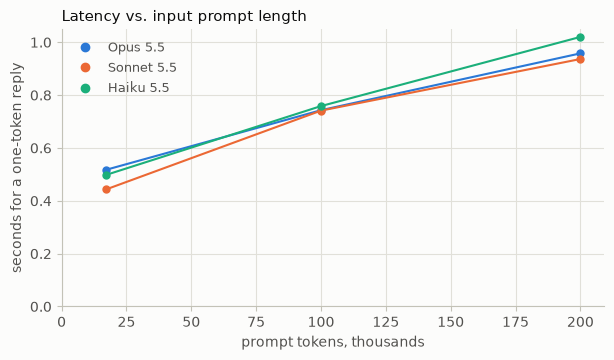

In [11]:
def read_prompt(model, ledger_rows):
    """A one-token reply to a prompt nobody has sent before, with no caching, so its seconds go to reading the
    prompt, plus a fixed overhead. Returns the prompt's tokens and the seconds"""
    paid = "\n".join((LEDGER_ROWS * 2)[:ledger_rows])
    system = f"(length {time.time_ns()})\n\n{MEMO_SYSTEM}\n\n=== PAID CLAIMS ===\n{paid}"
    request = single_request(QUESTION, Config(model, "low"), system=system, max_tokens=1)
    message, marks = timed_stream(**request)
    return message.usage.input_tokens, marks["done"]


# Ledger rows for about 17,000 prompt tokens (our tasks' size), 100,000, and 200,000
LENGTHS = (220, 3318, 7057)
runs = {(model, rows): [] for model in MODELS for rows in LENGTHS}
for repeat in range(3):
    order = list(runs)
    random.Random(repeat).shuffle(order)
    for model, rows in order:
        runs[model, rows].append(read_prompt(model, rows))

# Each point is its fastest run
CURVE = [
    {"model": NAME[model], "prompt tokens": got[0][0], "s": min(s for _, s in got)}
    for (model, rows), got in runs.items()
]
show(CURVE, places=2)
curve_chart(CURVE)

Going from the Desk Agent's 17,000 token input prompt to 200,000 tokens added about half a second on every model, which means roughly a quarter of a second per 100,000 tokens. That's a large share of the phone line's 0.70-second p90 TTFT, but a small part of the chat agent's 6.1-second p50, where most of the time goes to writing output. So for a near-real-time product, trimming the prompt can be a significant latency lever.

There are three approaches to sending fewer tokens:

- **Trim it.** Remove the parts of the prompt the task doesn't use. For images, [resize them](https://platform.claude.com/docs/en/build-with-claude/vision#evaluate-image-size) to the resolution the task needs, because a larger image costs more tokens and takes longer to process. In a long conversation, [context editing](https://platform.claude.com/docs/en/build-with-claude/context-editing) clears old tool results or thinking blocks the model no longer needs, and on the 5.5 models it [leaves earlier thinking valid](https://platform.claude.com/docs/en/build-with-claude/context-editing#context-editing-happens-server-side). If you use [prompt caching](#prompt-caching), each clear restarts the cache at that point, so the next call reads everything after it cold.
- **Defer it.** Keep context out of the prompt until the model needs it, also known as progressive disclosure. With [tool search](https://platform.claude.com/docs/en/agents-and-tools/tool-use/tool-search-tool), tools marked `defer_loading` stay out of the prompt until the model's search loads the ones it needs, which tends to pay off once tool definitions run past about 10,000 tokens. Skills do the same for instructions, where parts of a system prompt move behind a skill and load only when a task calls for them.
- **Make access efficient.** Give the model a narrower way to reach large context. A tool that returns the pages or fields a task needs keeps the rest of a long document out of the context. For tabular data, a CSV mounted into the [code execution tool](https://platform.claude.com/docs/en/agents-and-tools/tool-use/code-execution-tool) lets the model query it in a sandbox, so only the code and its output reach the context.

Each of these can add an extra call or more tokens downstream, so let your eval decide what your input shape should be.

<a id="prompt-caching"></a>
### Prompt caching

Our agent resends the same tools, system prompt, and conversation history on every call, and the model has to reprocess all of that content before it can start outputting tokens. [Prompt caching](https://platform.claude.com/docs/en/build-with-claude/prompt-caching) stores the content that the model has already seen so later calls don't need to reprocess it, which makes caching a great lever for cutting TTFT. The prefix is the part at the start of the prompt that repeats from call to call, including the tools, system prompt, and prior messages, and it ends at a cache breakpoint, the marker for how much of the prompt to cache. The simplest way to start is with [automatic caching](https://platform.claude.com/docs/en/build-with-claude/prompt-caching#automatic-caching): add a single top-level `cache_control` to your request, which places the breakpoint for you.

To add caching to the baseline, we use [explicit cache breakpoints](https://platform.claude.com/docs/en/build-with-claude/prompt-caching#explicit-cache-breakpoints) instead. This lets you place up to four breakpoints yourself, where each marks the end of a prefix that can be cached. Using more than one lets you match the parts of your prompt that change at different rates, so if a later part changes, the calls can still read the earlier ones from the cache. We'll use three of them here, with a `cache_control` marker on the system prompt, the first user turn, and the newest user turn. These are the lines that do it:

```python
system = [{"type": "text", "text": prompt, "cache_control": {"type": "ephemeral"}}]
...
    messages = list(history)
    for k in {0, len(messages) - 1}:
        *before, last = messages[k]["content"]
        messages[k] = {"role": "user", "content": [*before, {**last, "cache_control": {"type": "ephemeral"}}]}
```

Each request then sends `system` and `messages` instead of `prompt` and `history`. The next cell runs our eval with and without caching on all 154 tasks.

In [12]:
@dataclass(frozen=True)
class CachingConfig(Config):
    """A Config that also says whether the requests were cached, to tell the two baselines apart"""

    caching: str = "on"  # or "off"

    @property
    def name(self):
        return super().name + (" · caching" if self.caching == "on" else " · no caching")


BOTH = Sweep(["results/baseline.jsonl", "results/sweep.jsonl"], CachingConfig)
no_caching = CachingConfig(caching="off")
display(BOTH.results_table([CachingConfig()], base=no_caching, waits=tuple(MEASURES.values())))

# The baseline caches from here on. Every setting in the sweep ran with caching on
SWEEP = Sweep("results/sweep.jsonl", Config)

setting,correct,"correct vs first row, points",first token p90,first token p90 vs first row,p50,p50 vs first row,calls / task,output tokens / task,$ / task
Opus 5.5 · medium · no caching,99.0%,,0.70s,,6.1s,,3.5,861,$0.2512
Opus 5.5 · medium · caching,98.4%,-0.6 (-1.6 to +0.4),0.69s,×0.98 (0.94 to 1.01),6.2s,×1.01 (0.96 to 1.06),3.5,856,$0.0377


Caching cut the cost per task by 85% and didn't significantly change either product's wait or accuracy. The phone line's p90 TTFT went from 0.70 to 0.69 seconds and the chat agent's p50 TTLT from 6.1 to 6.2 seconds, both within run-to-run noise. Even if that small rise in p50 were real, we'd accept it to bring the cost per task from <span>&#36;</span>0.25 down to <span>&#36;</span>0.04, so caching stays on from here as the new baseline to beat. Our tasks are short and average 3.5 calls on prompts of about 17,000 tokens, so there's little prefix for a cache read to skip. 

The TTFT savings grow with the size of the prefix and the number of calls that reuse it, so on longer-horizon tasks with more turns they add up. The cell below times a two-turn conversation on a new system prompt of about 146,000 tokens, with no caching and then with the top-level `cache_control` added. The second turn resends the whole prompt and the first turn, which is where caching offers bigger latency wins. On that turn, `usage.cache_read_input_tokens` shows whether the cache was read. We run it on Haiku 5.5 at `low` effort, which keeps a prompt this long cheap to rerun, and report the median of five runs.

In [13]:
TURNS = (QUESTION, "What are its standard daily and aggregate limits?")


def long_system():
    """A system prompt of about 146,000 tokens that the cache has never seen"""
    return ledger_system(f"caching demo {time.time_ns()}")


def run_turns(system, cfg, cache):
    """Asks TURNS in one conversation. cache: turn on automatic caching. Returns the seconds until each
    answer began, and the tokens written to the cache and read from it"""
    history, calls = [], []
    for turn in TURNS:
        history.append({"role": "user", "content": turn})
        request = cfg.kwargs() | {"max_tokens": MAX_TOKENS, "system": system, "messages": history}
        if cache:
            request["cache_control"] = {"type": "ephemeral"}  # the one line that turns caching on
        m, marks = timed_stream(**request)
        history.append({"role": "assistant", "content": m.content})  # thinking blocks included
        calls.append(marks | token_counts(m.usage))
    waits = {f"turn {n}, s": c.get("text", c["done"]) for n, c in enumerate(calls, 1)}
    return waits | {
        "cache write, tokens": sum(c["cache_write"] for c in calls),
        "cache read, tokens": sum(c["cache_read"] for c in calls),
    }


cfg = Config(HAIKU, "low")
found = compare(
    {
        "BEFORE: no caching": lambda: run_turns(long_system(), cfg, cache=False),
        "AFTER: caching": lambda: run_turns(long_system(), cfg, cache=True),
    },
    repeats=5,
)
before, after = found.values()
show_medians(found, *before)
saved = before["turn 2, s"] - after["turn 2, s"]
print(f"\n→ {saved:.1f}s faster with {after['cache read, tokens']:,} tokens read from cache")

                     turn 1   turn 2   cache write, tokens   cache read, tokens
BEFORE: no caching     1.6s     1.7s                     0                    0
AFTER: caching         1.2s     0.5s               146,605              146,312

→ 1.2s faster with 146,312 tokens read from cache


Note that these savings last only while the prefix stays identical. A dynamic field at the top of the system prompt, such as a timestamp or a request ID, changes the prefix on every request and no longer matches what's been written to cache. Put [static content first](https://platform.claude.com/docs/en/build-with-claude/prompt-caching#structuring-your-prompt), mark its end with an explicit breakpoint, and put whatever varies after it in the newest user turn. Automatic caching alone won't do when requests share only that static part because it puts its breakpoint on the last block.

The same goes for the conversation. Editing an earlier turn restarts the cache from that point, and on recent models that support [preserved thinking](https://platform.claude.com/docs/en/build-with-claude/preserved-thinking) it can also get the request rejected. Changing the tools, thinking, effort, or model invalidates some or all of the cache too ([which parts](https://platform.claude.com/docs/en/build-with-claude/prompt-caching#what-invalidates-the-cache)). So only add to the end of `messages`, as a [mid-conversation system message](https://platform.claude.com/docs/en/build-with-claude/mid-conversation-system-messages) if you need one, and keep the model and its settings fixed. If cache reads drop to zero and you can't see why, [cache diagnostics](https://platform.claude.com/docs/en/build-with-claude/cache-diagnostics) shows what changed.

<a id="pre-warming"></a>
#### Pre-warming

A cache entry lives five minutes by default and is refreshed each time it's read, so the first request after more than five minutes of downtime pays for a cold prefix. [Pre-warming](https://platform.claude.com/docs/en/build-with-claude/prompt-caching#pre-warming-the-cache) moves that cost off the user's path. At startup, or on a timer inside the cache's lifetime, you send the shared prefix with an explicit breakpoint on its last block and `max_tokens: 0` so the model writes nothing. Use the same model, thinking configuration, and effort as the traffic that follows.

In the caching example above, the first turn is still slow because it reads all 146,000 tokens of the prompt cold. The cell below reruns that conversation with caching on, once as is and once after a pre-warm.

In [14]:
def prewarm(system, cfg):
    """Writes system into the cache ahead of real traffic, and returns it. cfg: that traffic's setting.
    max_tokens=0 generates nothing and can't stream"""
    request = single_request("warmup", cfg, system=system, cache=True, max_tokens=0)
    client.with_options(max_retries=2).messages.create(**request)
    return system


found = compare(
    {
        "BEFORE: no pre-warm": lambda: run_turns(long_system(), cfg, cache=True),
        "AFTER: pre-warmed": lambda: run_turns(prewarm(long_system(), cfg), cfg, cache=True),
    },
    repeats=5,
)
before, after = found.values()
show_medians(found, *before)
saved = before["turn 1, s"] - after["turn 1, s"]
more = after["cache read, tokens"] - before["cache read, tokens"]
print(f"\n→ {saved:.1f}s faster with {more:,} more tokens read from cache")

                      turn 1   turn 2   cache write, tokens   cache read, tokens
BEFORE: no pre-warm     1.0s     0.5s               146,615              146,312
AFTER: pre-warmed       0.8s     0.6s                   308              292,609

→ 0.2s faster with 146,297 more tokens read from cache


Pre-warming cut the first answer's wait from 1.0 to 0.8 seconds on this 146,000-token prompt. The saving grows with prompt length, because a cold read takes longer the more tokens it has to process, as we measured in [§Sending fewer tokens](#sending-fewer-tokens). We'd pre-warm when the prefix is long and traffic comes in bursts, with quiet spells longer than the cache lives. For those spells a [one-hour cache](https://platform.claude.com/docs/en/build-with-claude/prompt-caching#1-hour-cache-duration) is the alternative to a timer, and where steady traffic already keeps the cache warm, a pre-warm only adds a billed request.

<a id="message-threads"></a>
### Message threads

Prompt caching saves the model from reprocessing the prefix, but every call still uploads the whole conversation for the API to validate and tokenize again. [Message threads](https://platform.claude.com/docs/en/build-with-claude/message-threads) keep the conversation on the server so you don't have to resend it. The first call sends everything as usual and creates the thread. Each later call sends its new messages with the ID of the previous response and leaves out the system prompt, tools, and earlier turns. Here's how you'd implement it:

```python
first = {"system": system, "messages": history, "thread": {"type": "create"}}
...
later = {"messages": [new_message], "thread": {"type": "continue", "previous_message_id": previous.id}}
```

A thread saves you from resending the conversation, which matters more as it fills up with images, documents, or hundreds of tool results. The cell below opens a conversation with scanned pages of Acme's claims ledger and asks a few questions about them, with and without a thread. The first call on a thread uploads the full conversation, so we'll report the median TTFT of the later calls. And we'll keep `cache_control` on every request because threads don't cache the prompt for us.

In [15]:
THREADS = "message-threads-2026-08-12"
LOST = ("thread_not_found", "thread_already_continued", "thread_continue_in_flight")
PAGES = (4, 8, 16)
cfg = Config(HAIKU, "low", thinking="disabled")


def scan(rows):
    """An image block of one page of the paid claims ledger, as a 300 dpi scan of about 1 MB"""
    page = plt.figure(figsize=(8.5, 11))
    page.text(0.05, 0.96, "\n".join(rows), family="monospace", size=7, va="top", parse_math=False)
    jpeg = io.BytesIO()
    page.savefig(jpeg, format="jpg", dpi=300, pil_kwargs={"quality": 90})
    plt.close(page)
    data = base64.b64encode(jpeg.getvalue()).decode()
    return {"type": "image", "source": {"type": "base64", "media_type": "image/jpeg", "data": data}}


SCANS = [scan(LEDGER_ROWS[80 * n : 80 * (n + 1)]) for n in range(max(PAGES))]
PAID_CLAIMS = [row.split(",")[0] for row in LEDGER_ROWS[10:290:40]]
TOKENS = {
    pages: client.messages.count_tokens(
        model=cfg.model, system=MEMO_SYSTEM, messages=[{"role": "user", "content": SCANS[:pages]}]
    ).input_tokens
    for pages in PAGES
}


def run_claims(pages, thread):
    """Opens a conversation with that many scanned pages, then asks about each of PAID_CLAIMS, with caching on. thread: create a
    thread on the first call and send each later call only its new message. Returns, over the calls after the first,
    the median seconds until the answer began and the median size of the request's JSON"""
    system = f"(threads {time.time_ns()})\n\n{MEMO_SYSTEM}"
    fixed = cfg.kwargs() | {"max_tokens": MAX_TOKENS, "cache_control": {"type": "ephemeral"}}
    history = [
        {"role": "user", "content": SCANS[:pages]},
        {"role": "assistant", "content": "I have the pages."},
    ]
    previous, calls = None, []
    for claim in PAID_CLAIMS:
        history.append({"role": "user", "content": f"What was paid on {claim}?"})
        whole = fixed | {"system": system, "messages": history}
        if thread:
            whole["thread"] = {"type": "create"}
        request = whole
        if thread and previous:  # the thread holds the system prompt and the earlier messages
            request = fixed | {"messages": history[-1:]}
            request["thread"] = {"type": "continue", "previous_message_id": previous}
        start, lost = time.perf_counter(), 0.0
        try:
            m, marks = timed_stream(betas=[THREADS], **request)
        except (anthropic.NotFoundError, anthropic.BadRequestError) as e:
            details = e.body.get("error", {}).get("details") if isinstance(e.body, dict) else None
            if (details or {}).get("error_code") not in LOST:
                raise
            # The thread can't be continued, so resend the conversation on a new one. The failed call's time counts
            request, lost = whole, time.perf_counter() - start
            m, marks = timed_stream(betas=[THREADS], **request)
        calls.append(
            {
                "TTFT, s": lost + marks.get("text", marks["done"]),
                "bytes": len(json.dumps(request, default=lambda block: block.to_dict())),
            }
        )
        history.append({"role": "assistant", "content": m.content})
        previous = m.id
    ttft, size = (statistics.median(c[k] for c in calls[1:]) for k in ("TTFT, s", "bytes"))
    return {
        "TTFT, s": ttft,
        "request": f"{size / 1e6:.1f} MB" if size >= 1e6 else f"{size / 1e3:.1f} KB",
    }


runs = {(pages, thread): [] for pages in PAGES for thread in (False, True)}
for repeat in range(3):
    order = list(runs)
    random.Random(repeat).shuffle(order)
    for pages, thread in order:
        runs[pages, thread].append(run_claims(pages, thread))

show(
    [
        {"": "AFTER: caching + thread" if thread else "BEFORE: caching", "pages": pages}
        | {"prompt tokens": TOKENS[pages]}
        | min(repeats, key=lambda run: run["TTFT, s"])
        for (pages, thread), repeats in runs.items()
    ],
    places=2,
)

                          pages   prompt tokens    TTFT   request
BEFORE: caching               4          30,165   0.61s    5.6 MB
AFTER: caching + thread       4          30,165   0.40s    0.3 KB
BEFORE: caching               8          49,209   0.82s   11.2 MB
AFTER: caching + thread       8          49,209   0.48s    0.3 KB
BEFORE: caching              16          87,297   1.27s   22.3 MB
AFTER: caching + thread      16          87,297   0.63s    0.3 KB


With 16 pages, the thread halved TTFT by cutting each request from 22 MB to 0.3 KB, and those savings grew with the number of pages. Notice how the thread saves upload time as opposed to tokens. Claude still reads the full conversation on every call, so our cost is the same with and without threads. We'd use a thread on any long or heavy multi-turn conversation, but our desk agent's typical tasks are a few calls of plain text, so there's little payload for a thread to save.

<a id="agent-loop-efficiency"></a>
## Agent loop efficiency

Latency also depends on how many times an agent calls the model. This is the calls × TTFT term in our equation: an agent that takes five calls to answer pays five TTFTs, plus the tool waits in between. The levers in this section aim to make fewer calls and parallelize the calls that need to stay.

<a id="background-compaction"></a>
### Background compaction

On long multi-turn tasks, the conversation can eventually outgrow the model's context window. To keep going, the earlier turns have to be condensed into a summary that takes their place. The API's [compaction](https://platform.claude.com/docs/en/build-with-claude/compaction) writes that summary for you. Writing it takes time, and the ways to trigger it differ in whether a user has to wait for it. [At a token threshold](https://platform.claude.com/docs/en/build-with-claude/compaction-threshold), the request that crosses it writes the summary first, which adds that wait to the turn. [On demand](https://platform.claude.com/docs/en/build-with-claude/compaction-on-demand), a separate request returns the summary, and if you send that request [in the background](https://platform.claude.com/docs/en/build-with-claude/compaction-background), no turn waits for it at all.

Our desk agent's tasks never get long enough to reach a threshold, so we'll use a separate chat example with ten claims, each pasting in about 8K tokens. We'll run it three ways: with no compaction, with compaction at a 50K-token threshold (the lowest the API accepts), and with background compaction once the prompt passes 50K tokens.

In [16]:
# Helpers shared by this demo and the per-turn effort demo in Model, effort, and thinking
SESSION_SYSTEM = (
    "You are a Senior Adjuster in Acme Insurance's auto claims unit, working a queue of claims "
    "in one session. Apply the underwriting manual below. For each claim reply in exactly two "
    f"lines and nothing else:\n{TWO_LINES}\n\n{MANUAL}"
)


def new_session():
    """A system prompt that no earlier session has cached, and an empty history"""
    return f"(session {time.time_ns()})\n\n" + SESSION_SYSTEM, []


def claim_file(i):
    cid = list(CLAIMS)[i]
    comparables = "\n".join([LEDGER_ROWS[0], *LEDGER_ROWS[1 + i * 270 : 1 + (i + 1) * 270]])
    return f"{claim_record(cid)}\n\nCOMPARABLE PAID CLAIMS\n{comparables}\n\nDecide claim {cid}."


def session_request(system, messages, **more):
    """What every request on a conversation shares. Two cache breakpoints: one at the end of the system prompt,
    and one the API places at the end of the history, asked for by the top-level cache_control"""
    return BASE.kwargs() | {
        "max_tokens": MAX_TOKENS,
        "system": [cached({"type": "text", "text": system})],
        "messages": messages,
        "cache_control": {"type": "ephemeral"},
        **more,
    }


def send_turn(label, system, history, **more):
    """Sends the conversation's next request and appends the reply to history as returned, thinking included.
    Returns its row of the session's table"""
    m, marks = timed_stream(**session_request(system, history, **more))
    history.append({"role": "assistant", "content": m.content})
    # A request that compacts before it answers makes two passes, and usage.iterations lists each
    parts = [token_counts(u) for u in getattr(m.usage, "iterations", None) or [m.usage]]
    sizes = [t["input_tokens"] + t["cache_read"] + t["cache_write"] for t in parts]
    return {
        "": label,
        "wait s": marks["done"],
        "prompt tokens": max(sizes),
        "cache read, tokens": parts[-1]["cache_read"],
        "cache write, tokens": parts[-1]["cache_write"],
        "output tokens": m.usage.output_tokens,
    }


# The compaction demo: one conversation of ten claims, run three ways
COMPACT_BETA = "compact-2026-09-04"  # compaction on demand
THRESHOLD_BETA = "compact-2026-01-12"  # compaction at a token threshold
COMPACT_AT = 50_000  # prompt tokens. Also the lowest threshold the API accepts
PAUSE = 4.0  # seconds between turns, standing in for the person reading. Not counted as waiting


def summarize(system, messages):
    """Compaction on demand. Model, system, thinking, effort, and cache_control match the conversation's,
    so the request reads the conversation's cached prefix"""
    extra = {"betas": [COMPACT_BETA], "compaction": {"type": "summarize"}}
    request = session_request(system, messages, **extra)
    return client.with_options(max_retries=2).beta.messages.create(**request)


def run_session(mode):
    """Ten claims in one conversation. mode: "none", "threshold" (compact inside the request that crosses it),
    or "background" (ask for a summary between turns, swap it in when ready). Returns one row for each turn"""
    system, history = new_session()
    extra = {}
    if mode == "threshold":
        trigger = {"type": "input_tokens", "value": COMPACT_AT}
        edits = [{"type": "compact_20260112", "trigger": trigger}]
        extra = {"betas": [THRESHOLD_BETA], "context_management": {"edits": edits}}
    if mode == "background":
        extra = {"betas": [COMPACT_BETA]}  # needed once the history holds a summary
    rows = []
    pending, held = None, 0  # the summary on its way, and how many messages it covers
    with ThreadPoolExecutor(max_workers=1) as pool:
        for i in range(len(CLAIMS)):
            if pending and pending.done():
                summary, pending = pending.result(), None
                if summary.stop_reason == "compaction":
                    # Replace exactly the messages the summary covers. Later turns stay after it
                    history[:held] = [{"role": "assistant", "content": summary.content}]
            history.append({"role": "user", "content": claim_file(i)})
            row = send_turn(f"turn {i + 1}", system, history, **extra)
            rows.append(row)
            last = i + 1 == len(CLAIMS)
            if mode == "background" and not (pending or last) and row["prompt tokens"] > COMPACT_AT:
                pending, held = pool.submit(summarize, system, list(history)), len(history)
            time.sleep(0 if last else PAUSE)
    return rows


SESSIONS = {
    "no compaction": run_session("none"),
    "BEFORE: at a threshold": run_session("threshold"),
    "AFTER: in the background": run_session("background"),
}
summary = [
    {
        "": label,
        "median wait s": statistics.median(r["wait s"] for r in rows),
        "longest wait s": max(r["wait s"] for r in rows),
        "largest prompt, tokens": max(r["prompt tokens"] for r in rows),
    }
    for label, rows in SESSIONS.items()
]
show(summary)
_, before, after = (row["longest wait s"] for row in summary)
print(f"\n→ longest wait: {before:.1f}s compacting at a threshold, {after:.1f}s in the background")

                           median wait   longest wait   largest prompt, tokens
no compaction                     3.3s           5.4s                   95,881
BEFORE: at a threshold            4.1s          21.4s                   55,674
AFTER: in the background          3.3s           4.9s                   69,755

→ longest wait: 21.4s compacting at a threshold, 4.9s in the background


Compacting at a threshold left one turn waiting 21.4 seconds while the summary was written. In the background, the longest wait was 4.9 seconds, in line with the 5.4 seconds with no compaction. The tradeoff is a bigger prompt, about 70,000 tokens at its peak against 56,000 at a threshold, because the turns sent while the summary was being written still carried the full history. If your conversations run long enough to compact and someone waits on every turn, we'd compact in the background and ask for the summary early enough that those turns still fit in the context window.

<a id="subagents"></a>
### Subagents

When a task splits into independent pieces, each piece can go to a subagent. With the Messages API, a subagent is just another request with its own `messages` array. It sees the context you give it and returns its answer to the main agent. Sent together, the pieces run in parallel and the task waits for the slowest one. If you're building on the [Agent SDK](https://code.claude.com/docs/en/agent-sdk/subagents) or [Claude Managed Agents](https://platform.claude.com/docs/en/managed-agents/multiagent-orchestration), both have their own subagent support. 

In the cell below, Opus 5.5 is the main agent deciding a claim, and it needs three facts from the claim record first. In the first run it looks them up itself, one turn at a time in its own conversation. In the second it hands them to three faster, cheaper Haiku 5.5 subagents and decides from their answers. Only Opus gets the underwriting manual, since the subagents just look up facts. Every request runs at `low` effort, and we'll check their answers to ensure accuracy doesn't degrade.

In [17]:
# Three facts the manual's fraud score (§5.1) turns on. Each is a lookup in the claim record
QUESTIONS = [
    "How many days passed between the loss and the report, and is a reason for the delay on file?",
    "How many prior claims fell in the 36 months before the loss date?",
    "Was a police report filed?",
]
CLAIM = claim_record("CLM-008")
ONE_LINE = "Answer in one terse line."
DECIDE = f"Decide the claim from these findings. Reply in exactly two lines:\n{TWO_LINES}"
ANSWER = "SUPERVISOR"  # the manual's fraud score comes to 4, and 3 to 5 means supervisor review
ORCHESTRATOR, SUBAGENT = Config(OPUS, "low"), Config(HAIKU, "low")
BEFORE, AFTER = "BEFORE: Opus 5.5 answers in turn", "AFTER: Haiku 5.5 subagents side by side"
GRADES = {BEFORE: [], AFTER: []}  # whether each decision matched ANSWER


def reply(cfg, system, messages):
    """Sends one conversation and adds the reply to it. Returns the seconds"""
    message, marks = timed_stream(**cfg.kwargs(), max_tokens=8192, system=system, messages=messages)
    messages.append({"role": "assistant", "content": message.content})
    return marks["done"]


def text(messages):
    """The text of the conversation's last reply"""
    return "".join(b.text for b in messages[-1]["content"] if b.type == "text")


def decide(messages, label):
    """The orchestrator, which has the manual, decides from the conversation so far. Returns the seconds"""
    messages.append({"role": "user", "content": DECIDE})
    secs = reply(ORCHESTRATOR, MEMO_SYSTEM, messages)
    GRADES[label].append(f"DECISION: {ANSWER}" in text(messages))
    return secs


def one_agent():
    """The orchestrator answers each question in turn in its own conversation, then decides. Returns the
    seconds"""
    messages, secs = [], 0.0
    for i, question in enumerate(QUESTIONS):
        ask = f"{question} {ONE_LINE}"
        messages.append({"role": "user", "content": f"{CLAIM}\n\n{ask}" if i == 0 else ask})
        secs += reply(ORCHESTRATOR, MEMO_SYSTEM, messages)
    decision = decide(messages, BEFORE)
    return {"answers, s": secs, "decision, s": decision, "total, s": secs + decision}


def subagent(question):
    """One subagent: a request with its own messages array and no manual. Returns its seconds and answer"""
    messages = [{"role": "user", "content": f"{CLAIM}\n\n{question} {ONE_LINE}"}]
    return reply(SUBAGENT, "You are a claims assistant.", messages), text(messages)


def with_subagents():
    """Subagents answer the questions side by side, then the orchestrator decides from their answers. Returns
    the seconds"""
    with ThreadPoolExecutor(max_workers=len(QUESTIONS)) as pool:
        found = list(pool.map(subagent, QUESTIONS))
    findings = "\n".join(f"{q}\n{answer}" for q, (_, answer) in zip(QUESTIONS, found, strict=True))
    messages = [{"role": "user", "content": f"{CLAIM}\n\nSubagents' findings:\n{findings}"}]
    secs = max(s for s, _ in found)
    decision = decide(messages, AFTER)
    return {"answers, s": secs, "decision, s": decision, "total, s": secs + decision}


found = compare({BEFORE: one_agent, AFTER: with_subagents}, repeats=5)
for label, medians in found.items():
    medians["decisions right"] = f"{sum(GRADES[label])}/{len(GRADES[label])}"
show_medians(found, "answers, s", "decision, s", "total, s", "decisions right")
before, after = (medians["total, s"] for medians in found.values())
print(f"\n→ with subagents the task waits ×{after / before:.2f} as long")

                                          answers   decision   total   decisions right
BEFORE: Opus 5.5 answers in turn             6.8s       3.1s    9.5s               5/5
AFTER: Haiku 5.5 subagents side by side      1.5s       4.2s    5.7s               5/5

→ with subagents the task waits ×0.60 as long


With subagents the task took 5.7 seconds instead of 9.5, and all five decisions were correct. The three answers came back in 1.5 seconds instead of 6.8 because they ran in parallel on a faster model. So when a task splits into independent lookups or checks, hand them to small subagents and give each one only the context it needs. We chose Haiku 5.5 for speed, which suits simple lookups like these. Subtasks that need greater judgment may call for a larger model, but we would expect the effect to still be directionally the same because of the subagent parallelism gains.

If your subagents start with the same long context, such as a shared document, initiating the subagents at once means each one reads the document uncached, because the cache entry isn't ready until the first response begins. To fix that, [pre-warm](#pre-warming) the shared context, or send one subagent first and the other subagents once its reply starts streaming.

<a id="prefetch-and-bigger-pages"></a>
### Prefetch and bigger pages

Sometimes your code knows which tool call the model will make first. When it does, your code can make that call itself, outside the agent loop, and put the result in the first user turn. Every desk agent task starts with `get_claim` for the claim the request names, and a quote also needs `get_estimate` for page 1 of that claim's estimate. **Prefetch** runs those lookups up front, which saves the model a round trip. **Bigger pages** doubles the estimate lines or ledger rows each lookup returns, so tasks that page through results need fewer lookups. Both make the opposite trade from [§Sending fewer tokens](#sending-fewer-tokens), adding input tokens to make fewer calls and pay fewer TTFTs. 

These lines replace the baseline's setup of tools and the first turn:

```python
prefetch, big_pages = "prefetch" in cfg.loop, "big_pages" in cfg.loop
...
tools = desk_agent.tool_specs(big_pages=big_pages)
first = desk_agent.first_turn(task, prefetch=prefetch, big_pages=big_pages)
```

And the table below shows prefetching and bigger pages each applied to our baseline eval.

In [18]:
LEVERS = ("prefetch", "bigger pages")
SWEEP.results_table([BASE.with_loop(name) for name in LEVERS])

setting,correct,"correct vs first row, points",p50,p50 vs first row,p90,p90 vs first row,calls / task,output tokens / task,$ / task
Opus 5.5 · medium,98.4%,,6.2s,,11.8s,,3.5,856,$0.0377
Opus 5.5 · medium + prefetch,99.4%,+1.0 (+0.0 to +2.1),5.3s,×0.87 (0.82 to 0.90),12.1s,×1.02 (0.90 to 1.08),2.4,846,$0.0340
Opus 5.5 · medium + bigger pages,98.5%,+0.2 (-1.4 to +1.6),5.5s,×0.90 (0.85 to 0.94),11.4s,×0.96 (0.86 to 1.01),3.3,829,$0.0373


Prefetch saved about one call per task and cut p50 by 13%. Bigger pages saved fewer calls and cut p50 by 10%. Neither lever changed p90 or accuracy significantly. Given those wins on p50 latency, we recommend prefetching whatever lookup your task always does first, such as pulling the order a refund request refers to, and returning bigger pages where tasks page through long results.

<a id="programmatic-tool-calling"></a>
### Programmatic tool calling

In a normal tool loop, the model is sampled again after every round of tool calls. It asks for a call, your code runs it, and the result goes back into the conversation before the model can ask for the next one. A job that pages through 20 results one after another pays for 20 of those round trips, each with its own TTFT. The model also reads every result in full, even when all it needs is their total.

With [programmatic tool calling](https://platform.claude.com/docs/en/agents-and-tools/tool-use/programmatic-tool-calling), the model writes one script that makes all the tool calls from a code execution container. The model isn't sampled between those calls and reads only what the script prints ([see the cookbook](https://platform.claude.com/cookbook/tool-use-programmatic-tool-calling-ptc)). The tradeoff is a fixed overhead for starting the container and writing the script, and every call the script makes still goes out to your code and back. Programmatic tool calling pays off on jobs with many calls or large results. Skip it when the model needs to read each result before choosing the next call, or when a job makes only a few calls with small results.

In the demo below, the model adds up a year of insurance payouts from a tool that returns them one page at a time. With direct calls, the model has to ask for each page in turn. With a script, code fetches the pages and the model reads only the total.

In [19]:
PAGE = 20
PAID = [row | {"paid_usd": float(row["paid_usd"])} for row in csv.DictReader(LEDGER_ROWS)]
LIST_CLAIMS = {
    "name": "list_paid_claims",
    "description": (
        f"One page of the claims paid in a state on one year's losses, {PAGE} to a page, the most the "
        "API returns. For the next page, pass the last page's next_cursor. Returns JSON: "
        '{"rows": [{"claim_id": str, "loss_date": "YYYY-MM-DD", "type": str, "paid_usd": float}], '
        '"next_cursor": str or null}. next_cursor is null on the last page.'
    ),
    "input_schema": {
        "type": "object",
        "properties": {
            "state": {"type": "string", "description": "Two letters"},
            "year": {"type": "integer"},
            "cursor": {"type": "string"},
        },
        "required": ["state", "year"],
    },
}


def list_paid_claims(state, year, cursor=None):
    """The simulated API. A cursor is the last claim of the page before, so no page can be asked for ahead of time"""
    rows = [r for r in PAID if (r["state"], r["loss_date"][:4]) == (state, str(year))]
    claim_ids = [r["claim_id"] for r in rows]
    if cursor and cursor not in claim_ids:
        return "ERROR: unknown cursor"
    start = claim_ids.index(cursor) + 1 if cursor else 0
    page = [{k: v for k, v in r.items() if k != "state"} for r in rows[start : start + PAGE]]
    more = start + PAGE < len(rows)
    return json.dumps({"rows": page, "next_cursor": page[-1]["claim_id"] if more else None})


REPORT = (
    "A regulator wants our Texas payouts on 2022 losses: the total paid, and the claim type we paid "
    "the most on."
)
REPORT_SYSTEM = (
    "You are an analyst in Acme Insurance's auto claims unit. Answer from the paid-claims API, using "
    "every matching claim. End with exactly two lines:\n"
    "TOTAL: <dollars and cents>\nTOP TYPE: <claim type>"
)
REPORT_KEY = "TOTAL: 2110804.91\nTOP TYPE: collision"  # worked out from the ledger
SCRIPTS = "code_execution_20260120"


def run_report(cfg, scripted):
    """Answers REPORT with the one tool, which the model calls directly or (scripted) from a script it writes"""
    tools, extra = [LIST_CLAIMS], {"cache_control": {"type": "ephemeral"}}
    if scripted:  # the pages go to the script, so the prompt doesn't grow: nothing to cache
        sandbox = {"type": SCRIPTS, "name": "code_execution"}
        tools, extra = [sandbox, LIST_CLAIMS | {"allowed_callers": [SCRIPTS]}], {}
    request = cfg.kwargs() | {"max_tokens": MAX_TOKENS, "system": REPORT_SYSTEM, "tools": tools}
    history, secs, tokens = [{"role": "user", "content": REPORT}], [], 0
    while len(secs) < 40:
        m, marks = timed_stream(**request, messages=history, **extra)
        secs.append(marks["done"])
        tokens += m.usage.output_tokens
        history.append({"role": "assistant", "content": m.content})
        if m.container:
            extra["container"] = m.container.id  # a paused script resumes only in its own container
        # A script's calls come back as tool_use too, and their results must be the whole message
        results = [
            {"type": "tool_result", "tool_use_id": b.id, "content": list_paid_claims(**b.input)}
            for b in m.content
            if b.type == "tool_use"
        ]
        if results:
            history.append({"role": "user", "content": results})
        elif m.stop_reason != "pause_turn":
            break
    answer = next((b.text for b in reversed(m.content) if b.type == "text"), "")
    reply = answer.replace("$", "").replace(",", "")
    return {
        "fetching pages, s": sum(secs[:-1]),
        "answering, s": secs[-1],
        "total, s": sum(secs),
        "output tokens": tokens,
        "correct": reply.rstrip().endswith(REPORT_KEY),
    }


before, after = run_report(BASE, scripted=False), run_report(BASE, scripted=True)
show([{"": "BEFORE: direct calls"} | before, {"": "AFTER: from a script"} | after])
saved, fewer = (before[k] - after[k] for k in ("total, s", "output tokens"))
print(f"\n→ {saved:.1f}s faster from a script, with {fewer:,} fewer output tokens")

                       fetching pages   answering   total   output tokens   correct
BEFORE: direct calls            17.3s       29.6s   46.8s           5,262      True
AFTER: from a script            26.8s        9.2s   36.0s             816      True

→ 10.8s faster from a script, with 4,446 fewer output tokens


Fetching the pages took 9.5 seconds longer from the script, but answering took 20.4 seconds less, so the whole job finished about 11 seconds sooner. Fetching was slower because those requests include writing the script. Answering was faster because the script added up the payouts in code and printed the total, so the model only had to report it. With direct calls, the model had to add up every payout from every page itself, which took about 4,400 more output tokens. 

Programmatic tool calling helps most when a job ends in a sum, a filter, or a count, which code does better than the model. Our desk agent tasks take only a few calls with small results, so we left programmatic tool calling out of the final sweep.

<a id="output-token-management"></a>
## Output token management

With input tokens and turns settled, the other variables in our latency formula concern output. The model writes output tokens one at a time, so every token it doesn't write shortens TTLT, thinking included. If your application needs only a decision and a one-line reason, every paragraph of explanation around that is time the user shouldn't need to wait on.

<a id="prompting-for-shorter-answers"></a>
### Prompting for shorter answers

While it may sound trivial, you can simply ask Claude to emit fewer tokens. Outlining the output shape you want, ideally with an example, keeps the model from over-narrating its way to the answer. The cell below asks the model to decide the same claim twice. The first time it can answer however it likes. The second time it has to reply in exactly two lines, a decision and a one-sentence reason.

In [20]:
question = claim_record("CLM-008") + "\n\nWrite up your decision on this claim."
shaped = f"{MEMO_SYSTEM}\n\nRespond in exactly two lines and nothing else:\n{TWO_LINES}"
found = compare(
    {
        "BEFORE: free-form": lambda: timed(single_request(question, system=MEMO_SYSTEM)),
        "AFTER: two lines asked for": lambda: timed(single_request(question, system=shaped)),
    }
)
show_medians(found, "done, s", "output tokens", "of which thinking")
before, after = found.values()
saved = before["done, s"] - after["done, s"]
fewer = before["of which thinking"] - after["of which thinking"]
print(f"\n→ asking for two lines: {saved:.1f}s sooner, with {fewer:,.0f} fewer thinking tokens")

                              done   output tokens   of which thinking
BEFORE: free-form            46.4s           4,913               2,083
AFTER: two lines asked for    4.9s             433                 296

→ asking for two lines: 41.5s sooner, with 1,787 fewer thinking tokens


Asking for two lines cut the decision from 46.4 seconds to 4.9. The model thought less too, about 300 tokens instead of 2,100, so a shorter answer means shorter reasoning. If your task requires deep reasoning but only a brief output, use [structured outputs](#structured-outputs) for the answer and set how much the model thinks with [effort](#effort). We recommend asking for a shape wherever the model writes more than anyone reads.

<a id="no-commentary"></a>
#### No commentary

We can also prompt the agent not to narrate between tool calls. The table below compares the baseline with a version that adds this instruction to the system prompt:

> Write no text outside your tool calls: no plans, notes, summaries or explanations. Nobody reads that text, and the customer waits while you write it. Fill in the recorder call's arguments exactly as the manual asks.

In [21]:
SWEEP.results_table([BASE.with_loop("no commentary")])

setting,correct,"correct vs first row, points",p50,p50 vs first row,p90,p90 vs first row,calls / task,output tokens / task,$ / task
Opus 5.5 · medium,98.4%,,6.2s,,11.8s,,3.5,856,$0.0377
Opus 5.5 · medium + no commentary,99.5%,+1.2 (+0.1 to +2.3),6.0s,×0.97 (0.93 to 1.02),12.0s,×1.01 (0.92 to 1.08),3.5,836,$0.0376


The no-commentary instruction changed neither p50 nor p90 significantly for our use case. It had little to cut because Opus 5.5 wrote the same amount on its way to the answer with or without it. Accuracy rose by a significant 1.2 points, which may come from the instruction's last sentence about filling in the recorder's arguments rather than from cutting commentary. This configuration is still worth testing when nobody reads the text your agent writes between tool calls, but check accuracy on each model you'd run it with, because commentary can help keep the model on track on long-horizon tasks.

<a id="structured-outputs"></a>
### Structured outputs

[Structured outputs](https://platform.claude.com/docs/en/build-with-claude/structured-outputs) enforce a shape rather than ask for one, by constraining the response to a JSON schema sent in `output_config.format`. The reply is then only the JSON, so there's no preamble to generate and no retry for output that fails to parse. The first request with a new schema takes longer, because the API has to turn the schema into rules that limit what the model can write. Those rules stay cached for 24 hours after their last use. Our desk agent already answers by using a custom tool that constrains model output like structured outputs, so a schema would save it nothing. If a free-text answer would come with a preamble or need parsing, send a schema instead, and keep it stable, because a changed or rarely used schema pays that first-request wait again.

<a id="model-effort-and-thinking"></a>
## Model, effort, and thinking

How many tokens a call writes also depends on how much the model thinks, and how fast they arrive depends on the model and its speed. The levers here change how much the model reasons or which model does the reasoning. That sets your application's intelligence ceiling, which is the hardest problem it can still handle. A lower effort or a smaller model may pass every task in your eval and still fail a harder request that shows up later. That's why these levers come after the ones that leave the model alone. The exception is fast mode, which serves the same Opus 5.5, just faster.

<a id="fast-mode"></a>
### Fast mode

[Fast mode](https://platform.claude.com/docs/en/build-with-claude/fast-mode) runs Opus 5.5 with a faster inference configuration, which gives up to 2.5 times the OTPS at two times the sticker price. The tables below compare fast mode with standard Opus 5.5 across effort levels.

In [22]:
for effort in reversed(EFFORTS):
    standard = Config(effort=effort)
    display(SWEEP.results_table([replace(standard, speed="fast")], base=standard, rounds=True))

setting,correct,"correct vs first row, points",p50,p50 vs first row,p50 ratio in each round,p90,p90 vs first row,p90 ratio in each round,calls / task,output tokens / task,$ / task
Opus 5.5 · high,99.4%,,6.6s,,,13.2s,,,3.5,943,$0.0399
Opus 5.5 · high · fast mode,99.2%,-0.2 (-1.2 to +1.0),2.9s,×0.44 (0.42 to 0.47),0.47 0.51 0.36,5.4s,×0.41 (0.35 to 0.45),0.39 0.47 0.37,3.5,961,$0.0804


setting,correct,"correct vs first row, points",p50,p50 vs first row,p50 ratio in each round,p90,p90 vs first row,p90 ratio in each round,calls / task,output tokens / task,$ / task
Opus 5.5 · medium,98.4%,,6.2s,,,11.8s,,,3.5,856,$0.0377
Opus 5.5 · medium · fast mode,99.2%,+0.8 (-0.6 to +2.1),2.8s,×0.45 (0.43 to 0.47),0.47 0.51 0.38,5.0s,×0.42 (0.37 to 0.46),0.46 0.45 0.36,3.5,869,$0.0766


setting,correct,"correct vs first row, points",p50,p50 vs first row,p50 ratio in each round,p90,p90 vs first row,p90 ratio in each round,calls / task,output tokens / task,$ / task
Opus 5.5 · low,98.1%,,5.3s,,,11.8s,,,3.4,755,$0.0348
Opus 5.5 · low · fast mode,97.7%,-0.4 (-1.9 to +1.0),2.5s,×0.47 (0.45 to 0.49),0.50 0.54 0.38,5.0s,×0.42 (0.38 to 0.48),0.44 0.47 0.36,3.4,764,$0.0699


At every effort, fast mode cut p50 and p90 by 53% to 59%. Accuracy didn't change significantly, but the cost per task about doubled (<span>&#36;</span>0.0766, compared with <span>&#36;</span>0.0377 at `medium`). If seconds are worth twice the standard price and the task needs Opus-5.5-level intelligence, then fast mode fits. If your tasks are made of many short calls, fast mode might not be worth it because its gain is mostly in OTPS rather than TTFT.

<a id="effort"></a>
### Effort

**[Effort](https://platform.claude.com/docs/en/build-with-claude/effort)** sets how thorough the model is. In terms of tokens, that means how much it spends on thinking, text, and tool calls. With adaptive thinking, the model itself decides how much to think and effort steers it. Lower effort trades some capability for fewer tokens and calls, which shortens a call's TTLT and leaves OTPS about where it was. Note that [available effort levels](https://platform.claude.com/docs/en/build-with-claude/effort#effort-levels) and defaults vary from model to model and generation to generation; for Opus 5.5 in the table below, the default is `medium`.

In [23]:
ON_BASELINE_LOOP = SWEEP.pick(**LOOPS["baseline loop"])
table([SWEEP.result_row(Config(effort=effort), BASE, "medium") for effort in reversed(EFFORTS)])

setting,correct,"correct vs medium, points",p50,p50 vs medium,p90,p90 vs medium,calls / task,output tokens / task,$ / task
Opus 5.5 · high,99.4%,+1.0 (+0.0 to +2.1),6.6s,×1.07 (1.03 to 1.12),13.2s,×1.12 (1.04 to 1.24),3.5,943,$0.0399
Opus 5.5 · medium,98.4%,,6.2s,,11.8s,,3.5,856,$0.0377
Opus 5.5 · low,98.1%,-0.2 (-1.3 to +0.8),5.3s,×0.87 (0.83 to 0.91),11.8s,×1.00 (0.87 to 1.06),3.4,755,$0.0348


At `low`, Opus 5.5's p50 fell by a significant 13%, with no significant change in p90 or accuracy. At `high`, p50 rose 7% and p90 12%, both significant, and accuracy didn't change significantly. Those results suggest that relative to the complexity of our eval tasks, Opus 5.5 at `medium` effort might be over-levered, and we could win back latency by reducing effort. In general, start at the model's default, step down until your eval shows accuracy slipping, and only raise effort when the gain justifies the extra wait. We'll do this empirically in [§Putting it all together](#putting-it-all-together).

<a id="per-turn-effort"></a>
#### Per-turn effort

You can also change effort within a conversation, say from `low` to `high` when a hard problem comes in. On the 5.5 models, use the [per-message form](https://platform.claude.com/docs/en/build-with-claude/effort#change-effort-mid-conversation-beta), which persists your prompt cache by appending a system message with empty content and the new effort level. Changing the top-level `output_config.effort` would instead invalidate cached messages, so be sure to use the following syntax:

```json
{"role": "system", "content": [], "output_config": {"effort": "high"}}
```

The per-message form works on all 5.5 models with adaptive thinking, but not with Haiku 5.5's thinking off or Sonnet 5.5's `between_tools` (see [§Thinking off](#thinking-off)). In the cell below, Opus 5.5 decides four claims in one conversation at `high` effort. Only the fourth claim is hard, so if we match effort to difficulty, the first three can run at `low`, with a message raising effort to `high` for the fourth.

In [24]:
EFFORT_BETA = "mid-conversation-output-config-2026-07-01"
# Three routine claims, then one we want more care on
SESSION = ("CLM-001", "CLM-004", "CLM-005", "CLM-008")
KEY = {"CLM-001": "APPROVE", "CLM-004": "SIU", "CLM-005": "DENY", "CLM-008": "SUPERVISOR"}
BEFORE, AFTER = "BEFORE: high on every claim", "AFTER: low, then high for the last claim"
GRADES = {BEFORE: [], AFTER: []}  # whether each decision matched KEY


def work_session(label):
    """Decides the SESSION claims in one conversation on Opus 5.5. Returns the seconds"""
    system, history = new_session()
    effort = "high" if label == BEFORE else "low"
    secs = []
    for n, cid in enumerate(SESSION, 1):
        if label == AFTER and n == len(SESSION):
            # Raise effort in a message, which keeps the cache
            history.append({"role": "system", "content": [], "output_config": {"effort": "high"}})
        history.append({"role": "user", "content": claim_file(list(CLAIMS).index(cid))})
        extra = {"betas": [EFFORT_BETA], "output_config": {"effort": effort}}
        secs.append(send_turn(cid, system, history, **extra)["wait s"])
        answer = "".join(b.text for b in history[-1]["content"] if b.type == "text")
        GRADES[label].append(f"DECISION: {KEY[cid]}" in answer)
    return {
        "first three claims, s": sum(secs[:-1]),
        "last claim, s": secs[-1],
        "total, s": sum(secs),
    }


found = compare(
    {BEFORE: lambda: work_session(BEFORE), AFTER: lambda: work_session(AFTER)}, repeats=5
)
for label, medians in found.items():
    medians["decisions right"] = f"{sum(GRADES[label])}/{len(GRADES[label])}"
show_medians(found, "first three claims, s", "last claim, s", "total, s", "decisions right")
before, after = (medians["total, s"] for medians in found.values())
print(f"\n→ {before - after:.1f}s sooner with low effort on the routine claims")

                                           first three claims   last claim   total   decisions right
BEFORE: high on every claim                             12.6s         4.3s   17.3s             20/20
AFTER: low, then high for the last claim                 9.3s         3.7s   13.0s             20/20

→ 4.3s sooner with low effort on the routine claims


Running the three routine claims at `low` saved 3.3 seconds, and the conversation finished 4.3 seconds sooner while preserving 100% accuracy. So run routine turns at `low` and raise effort in a message only for the turns that need it. In production, something has to decide which turns those are, such as the task type or a classifier. How much you save depends on your mix of turns, so measure it on your own conversations.

<a id="model"></a>
### Model

A smaller model, like Sonnet or Haiku, usually writes output tokens faster, which shortens tasks where most of the time goes to writing output. That's true of our desk agent, where output tokens add more to a task's seconds than the fixed cost of each call. The next cell measures how fast each model writes by comparing every call's seconds with its output tokens. How much longer a call takes for each extra token gives OTPS, and what's left over is the fixed time every call takes, roughly TTFT plus network time.

setting,output tokens per second,calls / task,output tokens / task,from calls,from tokens
Opus 5.5 · medium,153,3.5,856,1.9s,5.6s
Sonnet 5.5 · medium,236,3.3,870,1.0s,3.7s
Haiku 5.5 · medium,581,3.9,"2,492",1.2s,4.3s


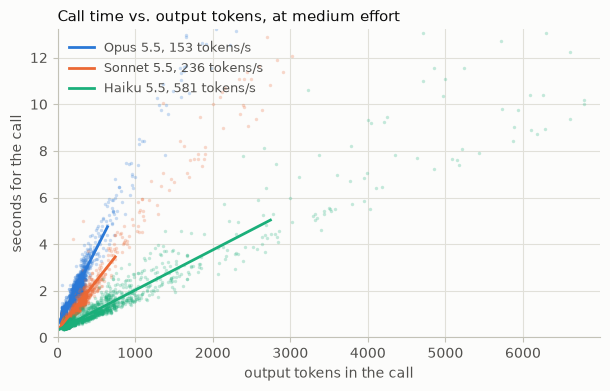

In [25]:
# The three models at medium effort and standard speed
MEDIUM = [
    cfg
    for cfg in ON_BASELINE_LOOP
    if cfg.effort == "medium" and cfg.thinking == "adaptive" and cfg.speed == "standard"
]
rows = []
for setting in MEDIUM:
    a, b = SWEEP.fit(setting)  # a call's seconds = a + b per 100 output tokens
    calls = SWEEP.value(setting, "calls")
    out = SWEEP.value(setting, "output_tokens")
    rows.append(
        {
            "setting": setting.name,
            "output tokens per second": round(100 / b),
            "calls / task": calls,
            "output tokens / task": round(out),
            # what calls and tokens each add to the average task's seconds
            "from calls, s": calls * a,
            "from tokens, s": out * b / 100,
        }
    )
display(table(rows))
speed_chart(SWEEP, MEDIUM)

Haiku 5.5 is the [fastest model in the current lineup](https://platform.claude.com/docs/en/models/overview), writing 581 tokens a second against Sonnet 5.5's 236 and Opus 5.5's 153. But faster tokens don't always mean a faster task. Notice how Haiku 5.5's calls stretch much further right, because it writes more tokens to achieve the same task. Smaller models are faster, but that doesn't mean they're more efficient.

The table below compares Sonnet 5.5 and Haiku 5.5 at `high`, `medium`, and `low` against the Opus 5.5 baseline. Watch accuracy and output tokens as well as the seconds.

In [26]:
SMALLER = [cfg for cfg in ON_BASELINE_LOOP if cfg.model != OPUS and cfg.thinking == "adaptive"]
SWEEP.results_table(SMALLER, rounds=True)

setting,correct,"correct vs first row, points",p50,p50 vs first row,p50 ratio in each round,p90,p90 vs first row,p90 ratio in each round,calls / task,output tokens / task,$ / task
Opus 5.5 · medium,98.4%,,6.2s,,,11.8s,,,3.5,856,$0.0377
Sonnet 5.5 · high,97.5%,-0.8 (-2.5 to +0.8),4.0s,×0.65 (0.61 to 0.69),0.64 0.68 0.64,8.7s,×0.74 (0.67 to 0.83),0.76 0.69 0.78,3.4,"1,008",$0.0201
Sonnet 5.5 · medium,94.4%,-3.9 (-6.4 to -1.3),3.5s,×0.57 (0.53 to 0.62),0.56 0.58 0.57,8.1s,×0.69 (0.59 to 0.74),0.63 0.68 0.76,3.3,870,$0.0184
Sonnet 5.5 · low,95.3%,-3.1 (-5.2 to -1.0),3.4s,×0.55 (0.51 to 0.59),0.53 0.57 0.55,7.9s,×0.67 (0.58 to 0.71),0.61 0.68 0.71,3.3,827,$0.0178
Haiku 5.5 · high,97.5%,-0.9 (-2.1 to +0.2),4.9s,×0.79 (0.75 to 0.85),0.83 0.72 0.81,15.7s,×1.33 (1.10 to 1.47),1.51 1.09 1.44,4.0,"3,441",$0.0028
Haiku 5.5 · medium,96.0%,-2.4 (-4.8 to +0.0),4.0s,×0.64 (0.60 to 0.69),0.69 0.60 0.64,12.2s,×1.03 (0.81 to 1.13),1.10 0.88 1.14,3.9,"2,492",$0.0023
Haiku 5.5 · low,90.4%,-8.0 (-11.0 to -5.3),3.6s,×0.58 (0.55 to 0.62),0.64 0.53 0.58,9.8s,×0.82 (0.68 to 0.94),0.98 0.66 0.87,3.8,"2,017",$0.0020


At `medium`, the same effort as the Opus 5.5 baseline, Sonnet cut the median task time by 2.7 seconds and Haiku by 2.2. Sonnet was faster because it wrote far fewer output tokens than Haiku, even though Haiku was emitting its extra tokens faster. That's even more apparent at p90, where Haiku at `high` took 3.9 seconds longer than Opus. Both Sonnet and Haiku were less accurate at `medium`, however, by 3.9 and 2.4 points respectively, so the time they save comes out of quality. And while cost per task falls steadily with model size, by about 2x on Sonnet and 16x on Haiku, accuracy and latency don't. Haiku at `high` scored 2.2 points higher than Sonnet at `low` but took 7.8 seconds longer at p90. 

The lesson here is to compare settings on your eval rather than by model size and sticker price alone, as we do in [§Putting it all together](#putting-it-all-together). For speed, we recommend moving only jobs that need little reasoning to a smaller model.

<a id="thinking-off"></a>
### Thinking off

Thinking is the reasoning a model writes before and between its answers and tool calls. It's a large part of what makes a model capable, so turning it off is for when speed matters more than accuracy. Haiku 5.5 is the only one of the three models that accepts `thinking: {"type": "disabled"}`, and Sonnet 5.5's lowest thinking setting is [`thinking: {"type": "between_tools"}`](https://platform.claude.com/docs/en/build-with-claude/prompt-engineering/prompting-claude-sonnet-5-5#running-without-up-front-thinking), which turns off up-front thinking. Both work only at `high` effort or below.

We ran Haiku 5.5 with thinking off at all three effort levels, and the cell below compares each against Haiku 5.5 at `high` with thinking on.

In [27]:
# Against Haiku 5.5 at high with thinking on, not the Opus 5.5 baseline
THINKING_ON = Config(HAIKU, "high")
THINKING_OFF = [cfg for cfg in ON_BASELINE_LOOP if cfg.thinking == "disabled"]
SWEEP.results_table(THINKING_OFF, base=THINKING_ON, rounds=True)

setting,correct,"correct vs first row, points",p50,p50 vs first row,p50 ratio in each round,p90,p90 vs first row,p90 ratio in each round,calls / task,output tokens / task,$ / task
Haiku 5.5 · high,97.5%,,4.9s,,,15.7s,,,4.0,"3,441",$0.0028
Haiku 5.5 · high · thinking off,73.5%,-24.0 (-27.8 to -20.2),3.7s,×0.76 (0.71 to 0.79),0.75 0.77 0.76,8.9s,×0.56 (0.50 to 0.61),0.56 0.56 0.57,3.8,"1,962",$0.0020
Haiku 5.5 · medium · thinking off,70.9%,-26.6 (-30.7 to -22.5),3.4s,×0.71 (0.67 to 0.74),0.72 0.70 0.69,7.7s,×0.49 (0.46 to 0.55),0.47 0.48 0.52,3.8,"1,739",$0.0019
Haiku 5.5 · low · thinking off,72.0%,-25.5 (-29.7 to -21.0),3.3s,×0.67 (0.62 to 0.69),0.70 0.68 0.63,7.6s,×0.48 (0.44 to 0.53),0.45 0.51 0.49,3.8,"1,574",$0.0017


At `high`, turning thinking off cut Haiku 5.5's p50 by 1.2 seconds and its p90 by 6.8, but accuracy fell 24 points. Lowering effort saved a little more time but still degraded accuracy. The speed gains cost roughly one answer in four, so when it comes to your own agents, we recommend only keeping thinking off if your eval shows accuracy holding.

Sonnet 5.5's `between_tools` works differently from turning thinking off. It skips the thinking before a reply's first output and keeps a lighter amount between tool calls. That saves time only when a reply would otherwise open with a long think. Our desk agent's replies always start with a lookup, which leaves nothing to skip. But it makes a bigger difference when we prompt for a long written reply. The cell below asks Sonnet 5.5 at `high` to write up its decision on a claim, once with adaptive thinking and once with `between_tools`, and checks whether each decision is right.

In [28]:
MEMO_DECISION = (
    claim_record("CLM-008") + "\n\nWrite an adjudication memo covering coverage analysis, damages, "
    "fraud review, authority, and a final recommendation. End the memo with exactly these two "
    f"lines:\n{TWO_LINES}"
)
MEMO_GRADES = {"adaptive": [], "between_tools": []}


def sonnet_memo(thinking):
    """Streams the memo on Sonnet 5.5 at high effort. Returns its seconds and token counts"""
    cfg = Config(SONNET, "high", thinking=thinking)
    message, marks = timed_stream(**single_request(MEMO_DECISION, cfg, system=MEMO_SYSTEM))
    text = "".join(b.text for b in message.content if b.type == "text")
    decision = text.rpartition("DECISION:")[2].partition("WHY")[0]
    MEMO_GRADES[thinking].append("SUPERVISOR" in decision)
    counts = token_counts(message.usage)
    return {
        "first thing on screen, s": min(marks.values()),
        "done, s": marks["done"],
        "output tokens": counts["output_tokens"],
        "of which thinking": counts["thinking_tokens"],
    }


found = compare(
    {
        "BEFORE: adaptive thinking": lambda: sonnet_memo("adaptive"),
        "AFTER: between_tools": lambda: sonnet_memo("between_tools"),
    },
    repeats=5,
)
for medians, grades in zip(found.values(), MEMO_GRADES.values(), strict=True):
    medians["decisions right"] = f"{sum(grades)}/{len(grades)}"
show_medians(found, *next(iter(found.values())))
before, after = found.values()
print(
    f"\n→ text on screen {before['first thing on screen, s'] - after['first thing on screen, s']:.1f}s sooner "
    f"with between_tools, and done {before['done, s'] - after['done, s']:.1f}s sooner"
)

                            first thing on screen    done   output tokens   of which thinking   decisions right
BEFORE: adaptive thinking                   15.8s   33.9s           4,633               1,944               5/5
AFTER: between_tools                         0.5s   23.2s           3,217                   0               3/5

→ text on screen 15.2s sooner with between_tools, and done 10.7s sooner


With adaptive thinking, Sonnet 5.5 thought for about 1,900 tokens before writing, and the user had to wait for 15.8 seconds during that time. `between_tools` put text on screen in half a second and finished emitting its last token 10.7 seconds sooner. Yet speed came at the cost of accuracy again, with just three out of five decisions correct. So you can use Sonnet 5.5 with `between_tools` to limit TTFT and TTLT on reasoning-heavy tasks that a user waits on, but be sure to check accuracy on your evals.

<a id="limiting-the-longest-task"></a>
## Limiting the longest task

The levers so far shorten p50 and p90 latency, but none of them bounds p99. Our application needs levers that mitigate the most extreme wait times, which are often caused by erroneous trajectories like a call that stalls, a reply that runs on, or a loop that keeps looking things up. Limits come in two kinds: a **stop** is enforced from outside the model, by your code or by the API, while a **signal** is a count the model can see and pace itself to. You can count tokens, calls, or seconds to know when a task has gone on too long, using the following mechanisms:

| Limit | Kind | What it counts |
|---|---|---|
| `max_tokens` | Stop, by the API | Tokens |
| A task budget | Signal | Tokens |
| A turn cap | Stop, by your code | Calls |
| A last-call message | Signal | Calls |
| A timeout | Stop, by your code | Seconds |
| A clock shown to the model | Signal | Seconds |

Stops and signals work best together. A stop alone cuts the task off with no answer, and a signal alone won't help if a call stalls. With both, the model sees the limit coming and answers before the stop has to act. Pick the limit that matches the problem: seconds when a user is waiting, calls when loops are the risk, and tokens when replies run long.

#### Tokens: `max_tokens` and a task budget

`max_tokens` is a hard cap on how many tokens the model can emit on a given turn. The model doesn't see it, so a lower cap doesn't necessarily make it write less. Whenever thinking is on, the cap covers thinking and tool calls as well as text, so a low cap can end a request before any answer is written. Set it high enough that real answers don't reach it, and catch `stop_reason: "max_tokens"` the way you'd catch an error.

The API's limit on a whole agent loop's tokens, a [task budget](https://platform.claude.com/docs/en/build-with-claude/task-budgets), is not deterministically enforced. It's one allowance of tokens shared by every request in the loop, counting thinking, tool calls, tool results, and text. The model paces its work to the remaining budget, and too tight a budget can make the model stop early or skip steps. A budget limits seconds only indirectly, so when your limit is in seconds, the clock below is a better fit.

#### Calls: a turn cap and a last-call message

A cap on model calls is a crude stop for a loop that never records an answer. These lines stop the loop at `TURN_CAP`, 16 calls, and tell the model after its 15th call that its next is its last:

```python
while len(calls) < desk_agent.TURN_CAP:
    ...
    if len(calls) == desk_agent.TURN_CAP - 1:
        results = [f"{r}\n\n{desk_agent.TURN_CAP_MESSAGE}" for r in results]
```

Without the message, the cap would end the task mid-lookup with no answer, but with it the model spends its last call recording its best answer.

#### Seconds: a timeout and a clock

The model has no clock of its own, so it can't innately tell the difference between one second and ten minutes. If your task needs to complete in some amount of time, add the elapsed time against that limit to the end of the newest user message before each request. The model will pace its work to finish inside that limit and usually finishes well before it. The code snippet below adds a clock to our baseline, measured against a 60-second `TIME_LIMIT`:

```python
def add_clock(message, seconds):
    """Adds the elapsed time, against the limit, to the end of a user message"""
    clock, last = f"elapsed {seconds:.0f}s / {TIME_LIMIT}s", message["content"][-1]
    if last["type"] == "tool_result":
        last["content"] += f"\n\n{clock}"
    else:
        message["content"].append({"type": "text", "text": clock})


task_start = time.perf_counter()
while True:
    add_clock(history[-1], time.perf_counter() - task_start)  # the newest message only
    ...
```

Each earlier clock stays where it is, so the cached prefix still matches on the next request. In cases where the model doesn't respect the clock, you should define a timeout in code. Set each stop above what your healthy tasks need, so it only catches runaway ones, and decide what the user sees when one fires, such as a partial answer, a retry, or a handoff. Before you set any of these stops, count how often each would have fired on your recorded tasks, since each of those tasks would have ended with no answer. The next cell does that for the sweep.

In [29]:
rows = []
for model, name in NAME.items():
    runs = [line for (cfg, _), got in SWEEP.rows.items() if cfg.model == model for line in got]
    outputs = [tokens for line in runs for tokens in line["call_output_tokens"]]
    rows.append(
        {
            "model": name,
            "task runs": len(runs),
            f"over {TIME_LIMIT}s": sum(line["secs"] > TIME_LIMIT for line in runs),
            "most calls in a task": max(len(line["call_secs"]) for line in runs),
            f"calls at {MAX_TOKENS:,} output tokens": sum(t >= MAX_TOKENS for t in outputs),
        }
    )
show(rows)

model        task runs   over 60s   most calls in a task   calls at 16,000 output tokens
Opus 5.5         6,893          0                      5                               0
Sonnet 5.5       2,760          0                      5                               0
Haiku 5.5        5,519          0                      8                               1


In the sweep, a 60-second timeout wouldn't have ended any of the 15,172 task runs, no task took more than 8 of its 16 calls, and only 1 call reached `MAX_TOKENS`. The stops cost almost nothing while capping how long any user waits, so `run_task()` in [§Putting it all together](#putting-it-all-together) keeps all three, plus the last-call message. We didn't proceed with a task budget or a clock because our tasks are short and take few calls, which leaves the model little to pace.

<a id="user-experience-design"></a>
## User experience design

No matter how good a model or harness is, there's always some amount of wait time incurred. And in user-facing applications, how long that wait <i>feels</i> matters just as much as how long it is. The levers in this section put something on screen sooner, which shortens the perceived wait even when the total time stays the same.

<a id="streaming"></a>
### Streaming

[Streaming](https://platform.claude.com/docs/en/build-with-claude/streaming) sends the reply as it's generated, so the user starts reading at its first token instead of waiting for the whole reply. The API delivers the reply as a series of events, each carrying the next piece of text or tool input, and your application shows each piece as it arrives. Turning it on takes one change, streaming each request instead of calling `create()`. In the Python SDK it looks like this:

```python
with client.messages.stream(**request) as stream:
    for text in stream.text_stream:
        print(text, end="", flush=True)  # show each piece as it arrives
    message = stream.get_final_message()
```

Streaming can also save time in an agent loop. A reply's tool calls arrive one after another, and each finishes streaming before the reply does, so your loop can start each tool as soon as its call arrives instead of waiting for the whole reply. [Fine-grained tool streaming](https://platform.claude.com/docs/en/agents-and-tools/tool-use/fine-grained-tool-streaming) goes a step further and streams each tool's input as it's written, though the input may not be valid JSON until it's complete. Your application should stream whenever a user watches the reply arrive and start tools early when replies carry several tool calls.

<a id="ui-during-thinking-state"></a>
### UI during thinking state

Streaming only helps once output tokens are being emitted. With thinking on, the model thinks before it writes its answer, and by default the API doesn't send that thinking to the client. The [`display`](https://platform.claude.com/docs/en/build-with-claude/thinking#controlling-thinking-display) field defaults to `"omitted"`, which is also our baseline's setting. With it, nothing reaches the screen until the model finishes thinking. But if you set `display` to `"summarized"`, then the API streams a readable summary of thinking as it goes, so the user sees the model working instead of a blank screen.

In an agent loop, the short [progress updates](https://platform.claude.com/docs/en/build-with-claude/thinking#progress-updates) that Opus 5.5 and Sonnet 5.5 write between tool calls arrive as thinking, so an interface left on the default also goes quiet while the agent works. `"updates"` (in beta, with the `thinking-display-updates-2026-08-18` header) keeps the reasoning hidden and returns those notes readable. Without an API setting, your interface can also show which tool is running, such as "Searching the ledger…", which keeps the screen from going quiet. Sonnet 5.5's `between_tools` removes the empty screen another way, by skipping the think instead of showing it, as discussed in [§Thinking off](#thinking-off).

The cell below streams one memo, outside the agent loop, with the thinking omitted and then summarized. Watch the `first thing on screen` column.

In [30]:
MEMO = (
    claim_record("CLM-008") + "\n\nWrite an adjudication memo covering coverage analysis, damages, "
    "fraud review, authority, and a final recommendation."
)


def memo(display):
    thinking = {"type": "adaptive", "display": display}
    return timed(single_request(MEMO, system=MEMO_SYSTEM, thinking=thinking))


found = compare(
    {
        "BEFORE: thinking omitted": lambda: memo("omitted"),
        "AFTER: thinking summarized": lambda: memo("summarized"),
    },
    repeats=5,
)
show_medians(found, "first thing on screen, s", "first answer text, s", "done, s", "output tokens")
before, after = found.values()
print(
    f"\n→ the screen stays empty for {before['done, s']:.1f}s without streaming, "
    f"{before['first thing on screen, s']:.1f}s streaming with the thinking omitted, "
    f"and {after['first thing on screen, s']:.1f}s with it summarized"
)

                             first thing on screen   first answer text    done   output tokens
BEFORE: thinking omitted                     26.3s               26.3s   64.5s           6,923
AFTER: thinking summarized                    4.2s               25.1s   58.2s           6,339

→ the screen stays empty for 64.5s without streaming, 26.3s streaming with the thinking omitted, and 4.2s with it summarized


The summary put text on screen 22.1 seconds sooner. Showing the thinking shouldn't change how long the model takes to answer, and the small differences in answer and finish time are within run-to-run variance. For an agent that someone follows on screen, we recommend showing something while it thinks, whether a summary of the thinking, the `"updates"` display, or a status line naming the current tool.

<a id="putting-it-all-together"></a>
## Putting it all together

Now that we've covered the different levers, let's decide which ones cut latency most for Acme's phone line (p90 TTFT) and chat agent (p50 TTLT). Testing every combination would blow past a reasonable budget, so we'll narrow the field first. Based on what the earlier sections showed, we'll sort the levers into those that have no negative impact on cost or accuracy, those that don't fit our use case, and those that need further testing. Then we'll shortlist what's left and run every combination, letting each product pick the fastest setting that clears its quality bar.

**Clear wins** (these help latency and cost without any tradeoff):

| Lever | Why it stays on |
|---|---|
| [Prompt caching](#prompt-caching) | Cut cost by 85% with no impact on latency or accuracy |
| [Streaming](#streaming), [UI during thinking](#ui-during-thinking-state) | Get something on screen sooner without changing task time |
| [Turn cap, last-call message, timeout](#limiting-the-longest-task) | Bound the worst case at almost no cost |
| [Structured answers](#structured-outputs) | Responses go through an answer tool with fixed fields |

**Ruled out** (these don't fit our product's shape, degrade latency, or result in accuracy below the quality bar):

| Lever | Why it's ruled out |
|---|---|
| [Sending fewer input tokens](#sending-fewer-tokens) | Most of our prompt is the policy manual the tasks need |
| [Pre-warming](#pre-warming) | Our prompt is too short for this to matter |
| [Message threads](#message-threads) | Our tasks take too few calls for the per-call saving to add up |
| [Background compaction](#background-compaction) | Each task is one short conversation that runs short of a compaction threshold |
| [Subagents](#subagents) | Our tasks are a few lookups in a row instead of independent pieces |
| [Programmatic tool calling](#programmatic-tool-calling) | Our tasks take few calls with small results |
| [No commentary](#no-commentary) | Our agent writes almost nothing between tool calls |
| [Per-turn effort](#per-turn-effort) | Each task is one job at one difficulty |
| [`between_tools`](#thinking-off) | Our replies open with a lookup so there's no up-front think to skip |
| [Thinking off](#thinking-off) | Failed the accuracy bar on every effort |

**Needs testing** (these sped things up on their own, but it's not yet clear how they'll interact with each other):

| Lever | Why it needs testing |
|---|---|
| [Prefetch](#prefetch-and-bigger-pages) | Cut task time on the baseline but slowed the first token |
| [Bigger pages](#prefetch-and-bigger-pages) | Cut task time on the baseline, only measured there |
| [Model](#model) | Smaller models wrote faster but sometimes wrote more |
| [Effort](#effort) | Lower effort was faster, with accuracy costs that varied by model |
| [Fast mode](#fast-mode) | Much faster on Opus 5.5 but twice the price |

We'll apply the clear wins as our new baseline and run a multivariate test with the levers that need testing. That's prefetch and bigger pages, each on or off, crossed with eight model settings: Haiku 5.5 at `medium` and `high`, Sonnet 5.5 at every effort, and Opus 5.5 with fast mode at every effort. Opus 5.5 at standard speed is left out because it was too slow for either product, and Haiku 5.5 at `low` because, at 90.4%, it was too far below the 95% bar for a loop change to close the gap. That makes 32 settings, each run on all 154 tasks for three rounds with the loop below.

In [31]:
def run_task(task, cfg):
    """Runs one task until it records an answer, gives up, or runs out of time. Returns its id, type, grade, and a row
    per model call that finished"""
    prefetch, big_pages = "prefetch" in cfg.loop, "big_pages" in cfg.loop
    prompt = desk_agent.system_prompt(no_commentary=cfg.commentary == "none")
    system = [cached({"type": "text", "text": prompt})]
    tools = desk_agent.tool_specs(big_pages=big_pages)
    first = desk_agent.first_turn(task, prefetch=prefetch, big_pages=big_pages)
    history = [{"role": "user", "content": [{"type": "text", "text": first}]}]
    calls, recorder, nudged = [], None, False
    deadline = time.perf_counter() + TIME_LIMIT
    while len(calls) < desk_agent.TURN_CAP:
        # Cache breakpoints on the first user turn and the newest one. They go on a copy, so the
        # history we keep never carries an old breakpoint
        messages = list(history)
        for k in {0, len(messages) - 1}:
            *before, last = messages[k]["content"]
            messages[k] = {"role": "user", "content": [*before, cached(last)]}
        try:
            m, marks = timed_stream(
                **cfg.kwargs(),
                max_tokens=MAX_TOKENS,
                system=system,
                tools=tools,
                messages=messages,
                deadline=deadline,
            )
        except TimeoutError:  # past TIME_LIMIT: nothing recorded, so it counts as wrong
            break
        history.append({"role": "assistant", "content": m.content})  # thinking blocks included
        uses = [b for b in m.content if b.type == "tool_use"]
        calls.append(
            {"secs": marks["done"], "tools": [b.name for b in uses], **token_counts(m.usage)}
        )
        if m.stop_reason in ("max_tokens", "refusal"):  # counts as wrong
            break
        recorder = next((b for b in uses if desk_agent.is_terminal(b.name)), None)
        if recorder or (nudged and not uses):
            break
        if not uses:  # one reminder, then the task ends with nothing recorded
            nudged = True
            reminder = {"type": "text", "text": desk_agent.NUDGE_MESSAGE}
            history.append({"role": "user", "content": [reminder]})
            continue
        with ThreadPoolExecutor(max_workers=8) as pool:  # one turn's lookups run side by side
            results = list(
                pool.map(
                    lambda b: desk_agent.call_tool(task, b.name, b.input, big_pages=big_pages), uses
                )
            )
        if len(calls) == desk_agent.TURN_CAP - 1:
            results = [f"{r}\n\n{desk_agent.TURN_CAP_MESSAGE}" for r in results]
        blocks = [
            {"type": "tool_result", "tool_use_id": b.id, "content": r}
            | ({"is_error": True} if r.startswith("ERROR: ") else {})
            for b, r in zip(uses, results, strict=True)
        ]
        history.append({"role": "user", "content": blocks})  # one message, in call order
    recorded = {"name": recorder.name, "args": recorder.input} if recorder else None
    correct = bool(desk_agent.grade(task, recorded)["correct"])
    return {"task": task["id"], "type": task["type"], "correct": correct, "calls": calls}

In [32]:
# Haiku 5.5 at low fell short of the bar on the baseline loop, so it's left out
RACE = Sweep(
    "results/race.jsonl",
    Config,
    keep=lambda line: (line["model"], line["effort"]) != (HAIKU, "low"),
    stop=TIME_LIMIT,
)
rows = [
    {
        "setting": cfg.name,
        "correct": f"{RACE.value(cfg, 'correct'):.1%}",
        "first token p90": f"{RACE.value(cfg, 'first token p90'):.2f}s",
        "p50": f"{RACE.value(cfg, 'p50'):.1f}s",
        "p90": f"{RACE.value(cfg, 'p90'):.1f}s",
        "$ / task": f"${RACE.value(cfg, 'usd'):.4f}",
    }
    for cfg in RACE.settings
]
display(table(rows))

setting,correct,first token p90,p50,p90,$ / task
Opus 5.5 · high · fast mode,100.0%,0.73s,3.7s,7.1s,$0.0804
Opus 5.5 · high · fast mode + prefetch,98.1%,1.19s,2.8s,6.1s,$0.0712
Opus 5.5 · high · fast mode + bigger pages,98.7%,0.72s,3.6s,6.4s,$0.0776
Opus 5.5 · high · fast mode + prefetch + bigger pages,99.4%,1.15s,2.7s,5.5s,$0.0678
Opus 5.5 · medium · fast mode,99.2%,0.77s,3.6s,6.7s,$0.0761
Opus 5.5 · medium · fast mode + prefetch,99.0%,1.03s,2.6s,5.9s,$0.0664
Opus 5.5 · medium · fast mode + bigger pages,98.4%,0.70s,3.3s,5.9s,$0.0729
Opus 5.5 · medium · fast mode + prefetch + bigger pages,97.9%,1.13s,2.4s,5.2s,$0.0641
Opus 5.5 · low · fast mode,98.8%,0.65s,2.9s,6.0s,$0.0689
Opus 5.5 · low · fast mode + prefetch,97.7%,0.92s,2.4s,5.7s,$0.0591


25 of the 32 settings cleared the 95% bar, but no single setting was fastest on every measure. Let's now isolate each product's measure, p50 TTLT for the chat agent and p90 TTFT for the phone line, to see which setting fits each. The fastest setting that meets the quality bar wins.

In [33]:
@dataclass(frozen=True)
class Bounds:
    """What a product fixes before it looks at any result"""

    bar: float  # the share of tasks it needs right
    metric: str  # the wait its users feel: "p50", "p90", "first token p50", or "first token p90"

    def outside(self, cfg):
        """Why the setting is out, in words. Empty if it meets the bar"""
        return "under the bar" if RACE.value(cfg, "correct") < self.bar else ""


PRODUCTS = {name: Bounds(bar=0.95, metric=metric) for name, metric in MEASURES.items()}
SETTINGS = list(RACE.settings)


def report(name, shown=8):
    """One product: the settings that meet its bar, fastest first at its metric, and the chart"""
    bounds = PRODUCTS[name]
    print(f"{name}: quality bar {bounds.bar:.0%}, ranked by {in_words(bounds.metric)}")
    inside = [cfg for cfg in SETTINGS if not bounds.outside(cfg)]
    inside.sort(key=lambda cfg: RACE.value(cfg, bounds.metric))
    pick = inside[0]
    rows = []
    for cfg in inside[:shown]:
        tied = cfg != pick and RACE.versus(cfg, pick, bounds.metric).verdict == "not significant"
        rows.append(rank_row(RACE, cfg, bounds, "" if cfg == pick else "yes" if tied else "no"))
    display(table(rows))
    title = f"{name}: every setting, by {in_words(bounds.metric)}"
    frontier_chart(RACE, SETTINGS, bounds, pick, title)

Chat agent: quality bar 95%, ranked by p50 seconds per task


setting,correct (hardest level),p50,p90,$ / task,tied with the fastest
Opus 5.5 · low · fast mode + prefetch + bigger pages,96.9% (90.3%),2.3s,5.1s,$0.0557,
Opus 5.5 · low · fast mode + prefetch,97.7% (90.3%),2.4s,5.7s,$0.0591,yes
Opus 5.5 · medium · fast mode + prefetch + bigger pages,97.9% (94.4%),2.4s,5.2s,$0.0641,yes
Opus 5.5 · medium · fast mode + prefetch,99.0% (96.3%),2.6s,5.9s,$0.0664,no
Opus 5.5 · high · fast mode + prefetch + bigger pages,99.4% (98.1%),2.7s,5.5s,$0.0678,no
Opus 5.5 · low · fast mode + bigger pages,97.5% (90.7%),2.8s,5.3s,$0.0653,no
Opus 5.5 · high · fast mode + prefetch,98.1% (90.4%),2.8s,6.1s,$0.0712,no
Opus 5.5 · low · fast mode,98.8% (94.4%),2.9s,6.0s,$0.0689,no


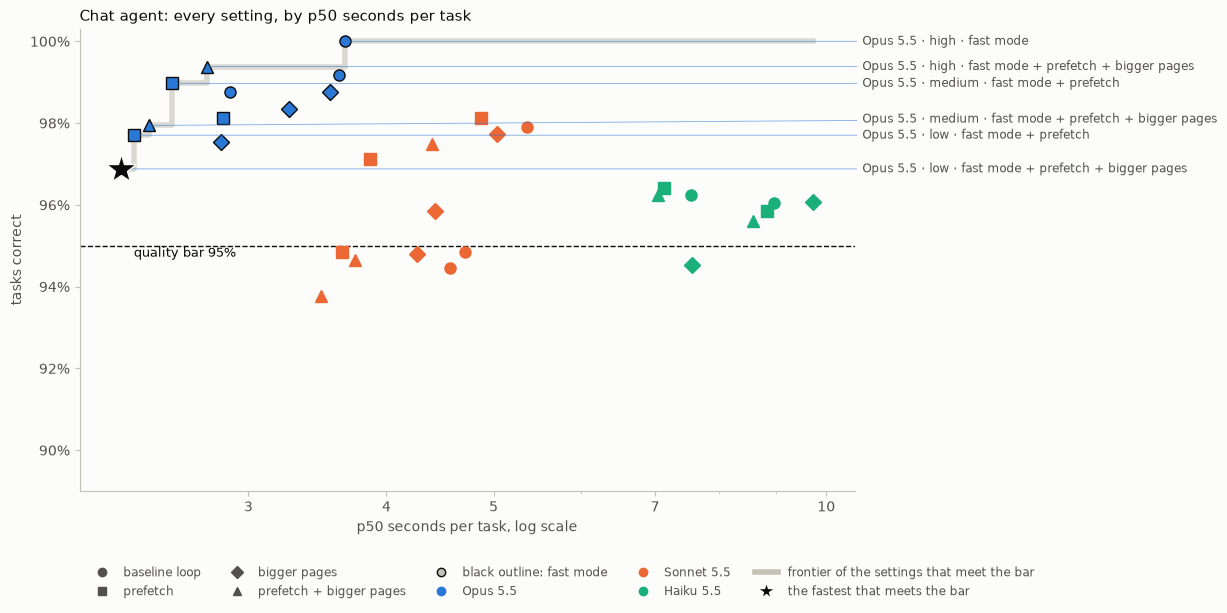

In [34]:
report("Chat agent")

**The chat agent**

- Our pick: Opus 5.5 at `low` with fast mode, prefetch, and bigger pages, with a p50 TTLT of 2.3 seconds at 96.9% accuracy and <span>&#36;</span>0.056 per task.
- If cost is a constraint: Sonnet 5.5 at `medium` with prefetch costs about a third as much, but it gives up about 1.6 seconds at p50 with 97.1% accuracy.
- Across models, most of the p50 speed gain came from prefetch. On Opus 5.5 at `low` with fast mode, prefetch cut p50 by about half a second by saving the agent's first lookup. On a task of only a few calls that's a large share of the wait.

Phone line: quality bar 95%, ranked by p90 seconds to the first visible token


setting,correct (hardest level),first token p90,p50,p90,$ / task,tied with the fastest
Opus 5.5 · low · fast mode,98.8% (94.4%),0.65s,2.9s,6.0s,$0.0689,
Opus 5.5 · low · fast mode + bigger pages,97.5% (90.7%),0.65s,2.8s,5.3s,$0.0653,yes
Sonnet 5.5 · medium + bigger pages,95.9% (92.6%),0.65s,4.4s,11.1s,$0.0175,yes
Sonnet 5.5 · high + bigger pages,97.7% (98.1%),0.69s,5.0s,13.2s,$0.0193,yes
Opus 5.5 · medium · fast mode + bigger pages,98.4% (96.3%),0.70s,3.3s,5.9s,$0.0729,yes
Sonnet 5.5 · high,97.9% (98.1%),0.71s,5.4s,13.2s,$0.0205,no
Opus 5.5 · high · fast mode + bigger pages,98.7% (94.4%),0.72s,3.6s,6.4s,$0.0776,yes
Opus 5.5 · high · fast mode,100.0% (100.0%),0.73s,3.7s,7.1s,$0.0804,no


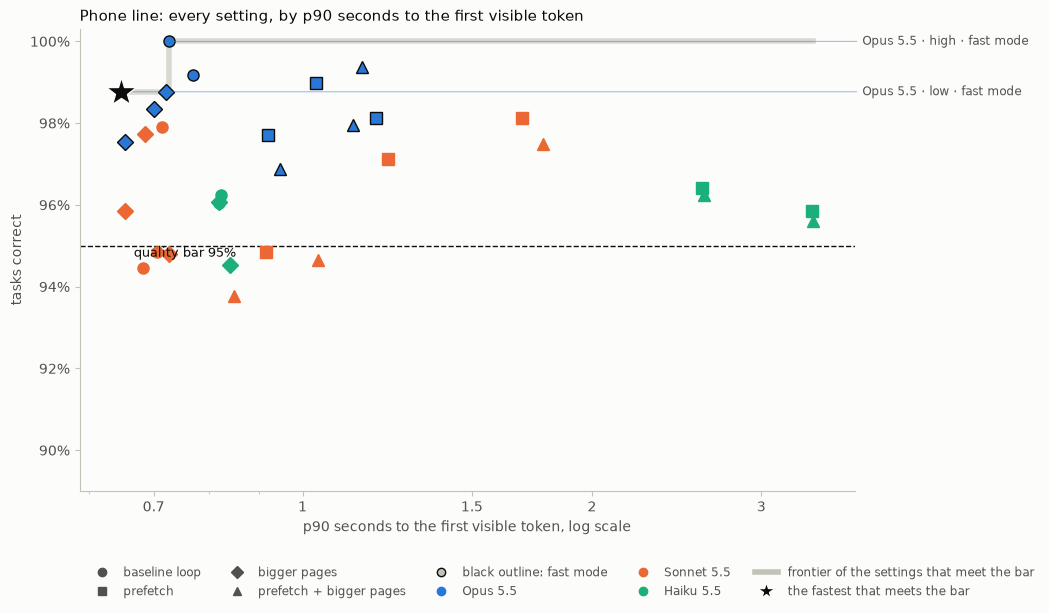

In [35]:
report("Phone line")

**The phone line**

- Our pick: Opus 5.5 at `low` with fast mode, with a p90 TTFT of 0.65 seconds at 98.8% accuracy and <span>&#36;</span>0.069 per task.
- If cost is a constraint: Sonnet 5.5 at `medium` with bigger pages is just as fast at about a quarter of the price and 95.9% accuracy. Its p90 TTLT is 5.1 seconds longer, though, so a caller waits longer for the full answer.
- For the phone line, the first token comes down to whether the first call thinks. Anything that makes it think, like prefetching the claim or choosing Haiku 5.5, pushes TTFT back. Model size and effort barely matter, and bigger pages don't seem to impact TTFT much.

<a id="takeaways-and-next-steps"></a>
## Takeaways and next steps

Our two products ended up on the same model, effort, and speed, Opus 5.5 at `low` with fast mode, but on different loops, because one is judged on its first token and the other on the whole task. The key lessons to apply to your own latency experimentation are:

1. **Start with an eval and a quality bar.** Some of the fastest settings fail on accuracy, so build an eval on your own tasks, decide the lowest quality you'll accept up front, and rerun it on every change.

2. **Design for <i>perceived</i> latency.** Optimize for the wait your users actually feel, depending on your product shape. Some notice how long it takes for anything to appear, while others notice how long the full answer takes, and speeding up one can slow down the other.

3. **Fix the loop before the model.** Fewer round trips save time without touching the model's reasoning, and they usually cut cost too. A smaller model or lower effort trades some accuracy for its speed.

4. **Output is usually where the time goes.** Ask for less of it, since a shorter answer often means shorter thinking too, and when a task needs deep reasoning but only a brief answer, use structured outputs and set effort separately. Fast mode or a smaller model writes output faster, but a model that writes faster can still finish later if it has to write more.

The table below starts from the outcome you want and lists the levers that move it. Use this as a quick cheat sheet when deciding which levers to pull first for reducing latency in your application.

| If you want… | Try |
|---|---|
| A faster first token | [Send fewer input tokens](#sending-fewer-tokens), cache a static prefix with [prompt caching](#prompt-caching), [pre-warm](#pre-warming) it for bursty traffic, and use [message threads](#message-threads) on long or image-heavy conversations; keep the first call from thinking with [lower effort](#effort), [`between_tools`](#thinking-off) on Sonnet 5.5, or [thinking off](#thinking-off) on Haiku 5.5 |
| Fewer calls to wait through | [Prefetch](#prefetch-and-bigger-pages) the lookup every task starts with and return [bigger pages](#prefetch-and-bigger-pages) for long results; use [programmatic tool calling](#programmatic-tool-calling) when a run of calls ends in a sum, a filter, or a count, and [subagents](#subagents) on a smaller model for independent lookups |
| Less output to wait for | Ask for a [short output shape](#prompting-for-shorter-answers) or use [structured outputs](#structured-outputs), and lower [effort](#effort) overall or [on routine turns](#per-turn-effort); ask for [no commentary](#no-commentary) if your agent writes text between tool calls |
| Faster output once it starts | Turn on [fast mode](#fast-mode) for Opus 5.5, or move jobs that need little reasoning to a [smaller model](#model) as long as it doesn't result in the model writing more |
| A shorter worst case | Cap the loop with a timeout and a turn cap and each call with `max_tokens`, and give the model a task budget or the elapsed time, per [§Limiting the longest task](#limiting-the-longest-task) |
| A wait that feels shorter | [Stream](#streaming) replies and show a thinking summary, progress updates, or the running tool [while the model works](#ui-during-thinking-state); [compact in the background](#background-compaction) so long conversations don't stall on a summary |

<a id="limitations"></a>
### Limitations

A few caveats apply before you carry our results over to your own agent:

- **The best levers depend on your specific use case.** Our workload is synthetic, and its tools answer instantly, so real lookups add waits that our figures leave out and expose a different set of opportunities for latency optimization.

- **Latency is nondeterministic.** Most demos report the median of a few runs, and results between models moved from round to round. Whether a lever helped or hurt is more reliable than exactly how much. Running more trials helps reduce noise but can become cost-prohibitive.

- **We focused testing on 5.5 models and the Messages API.** Output speed, thinking, and settings like fast mode can change between model generations, and the API levers in this cookbook may change as the platform evolves. The Agent SDK, Claude Code, and other frameworks also have their own levers that we don't cover here.

- **There are other factors that could be impacting your latency.** Latency also depends on things no lever here changes, like traffic load, time of day, rate limits, and your network and client. It also depends on whether you call the Claude API directly or through a cloud platform, and in which region.

<a id="conclusion"></a>
### Conclusion

There's no fastest universal configuration. Acme's phone line and chat agent started from the same agent and the same levers, and they still landed on different configurations because their users feel different waits. Your numbers will most likely differ from ours, but the method and best practices carry over. Set a quality bar and build an eval that holds you to it. Find which terms of the latency equation matter most to your users. Then test combinations of levers that could help, and ship the fastest setting that clears the bar.

Optimizing latency is also never finished. Your traffic and tasks will change, and new models and API features will open up levers this cookbook doesn't cover. Rerun your eval frequently and check whether today's pick is still the fastest.